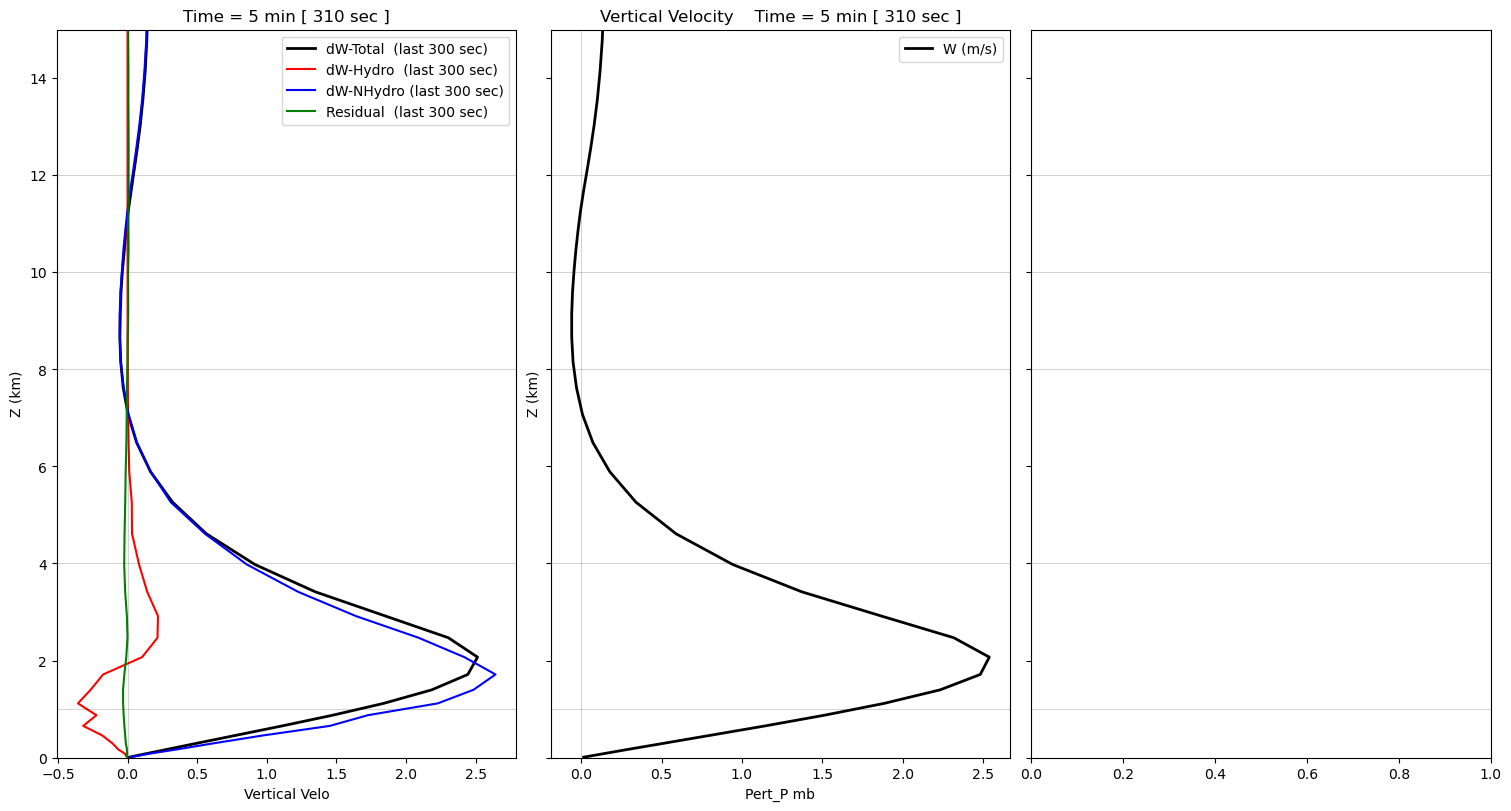

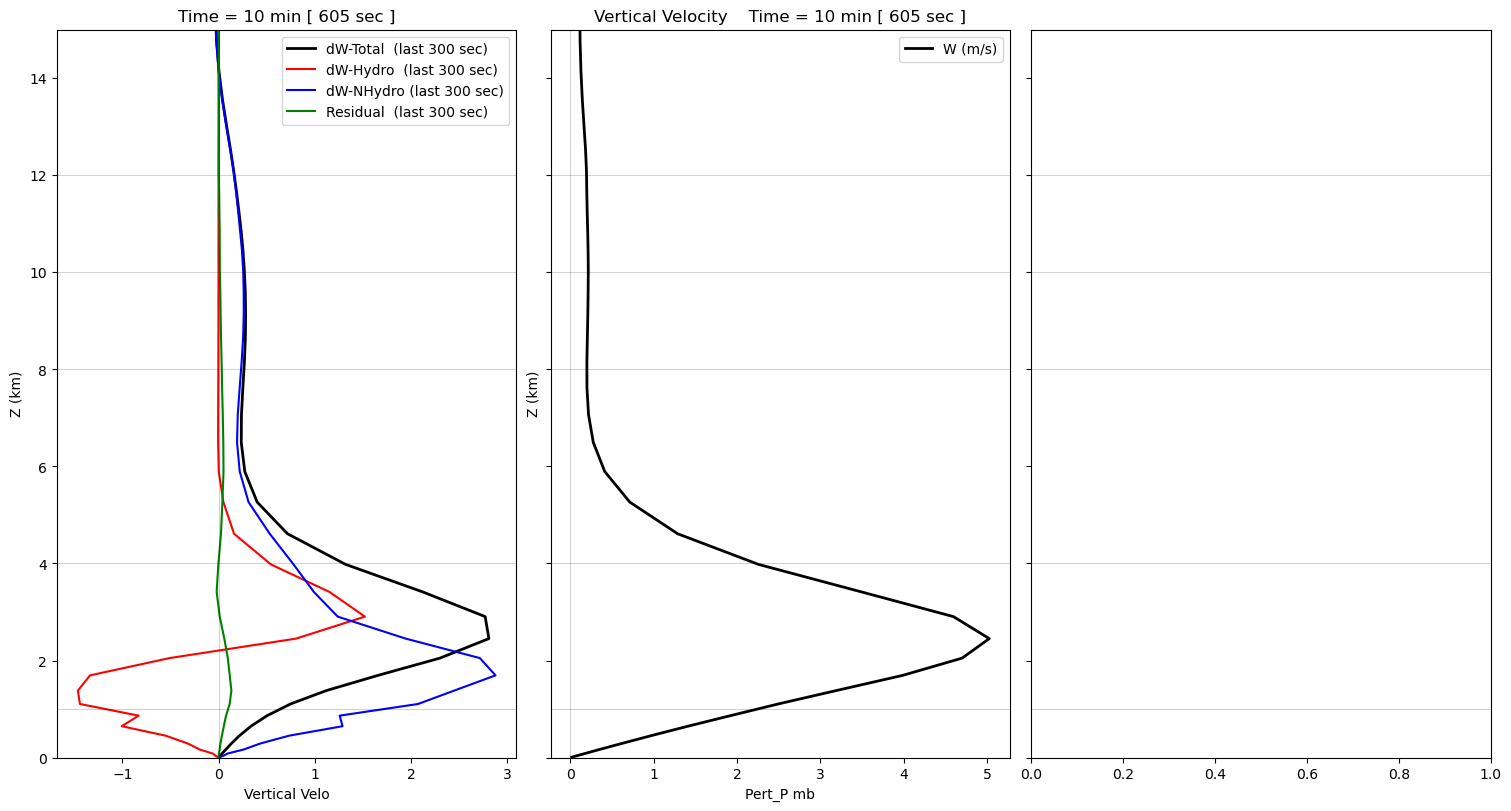

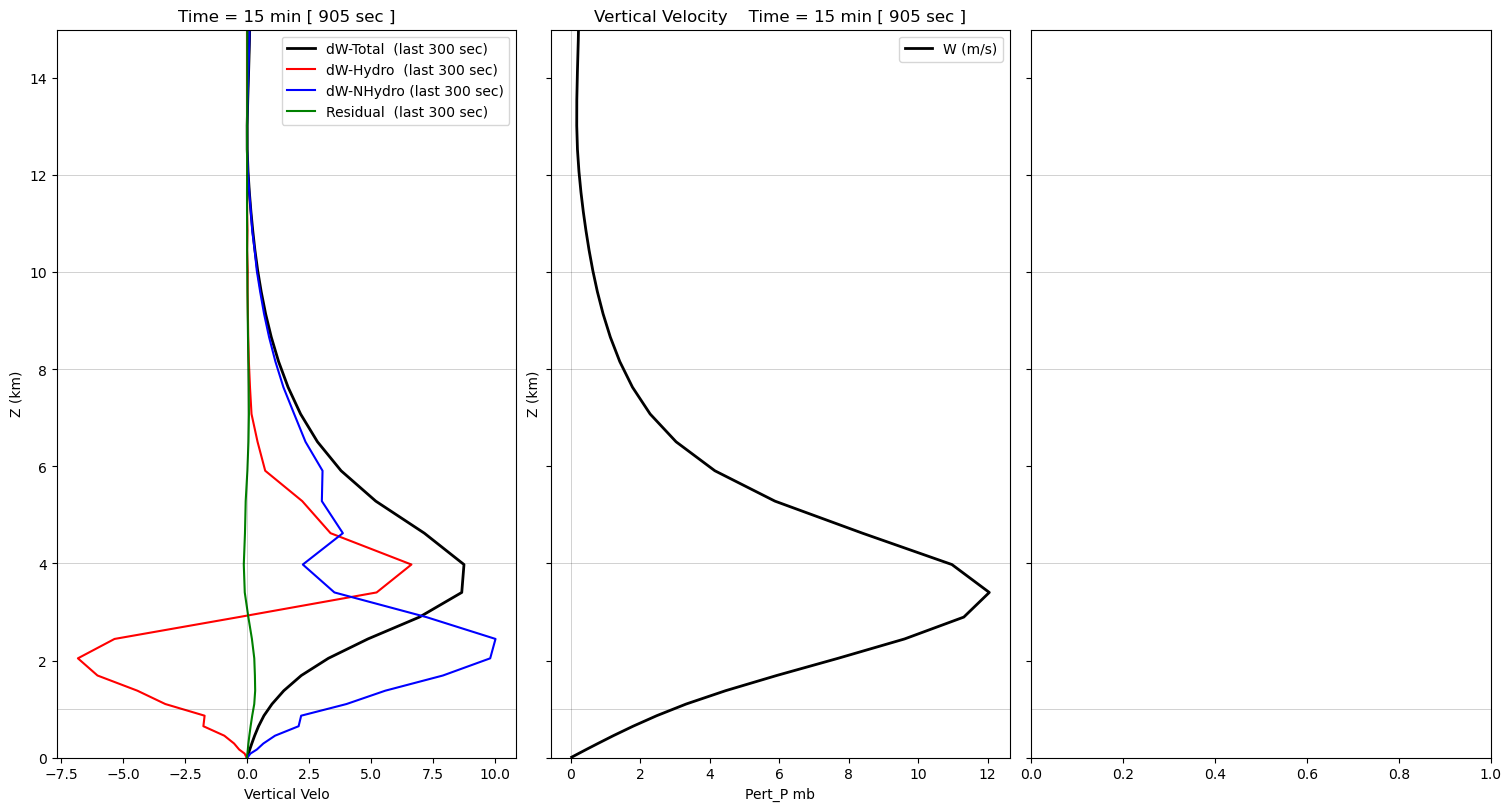

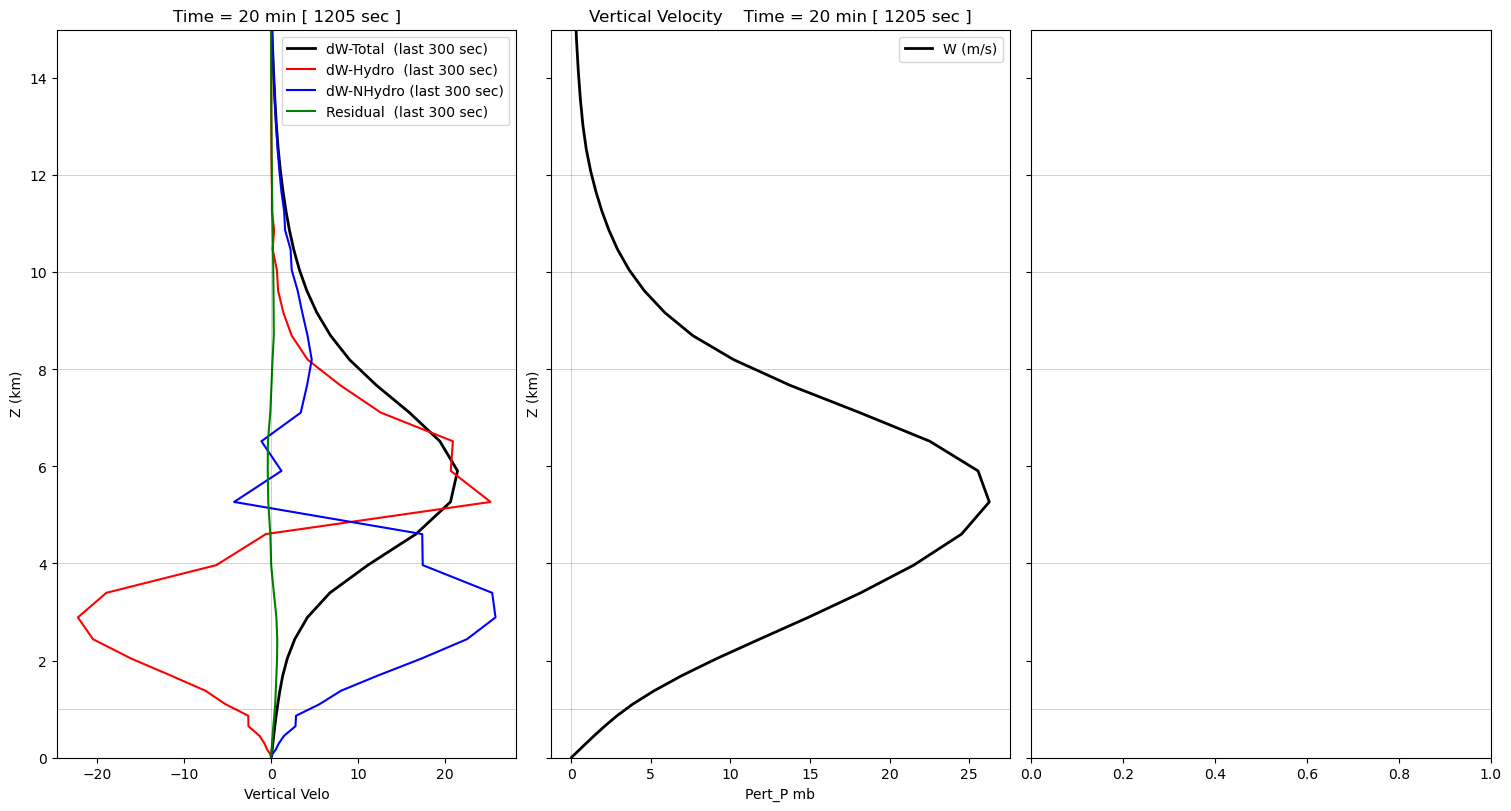

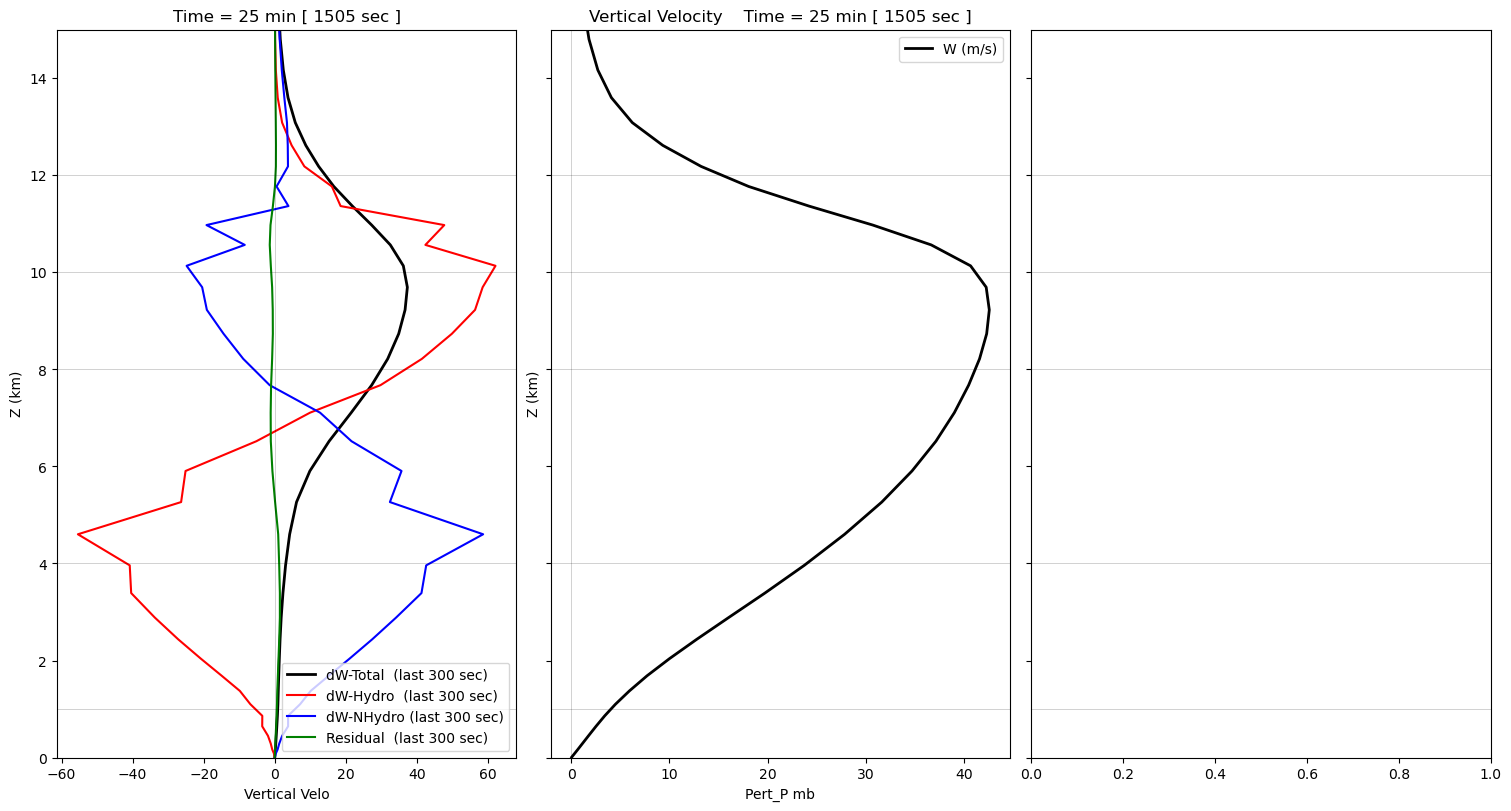

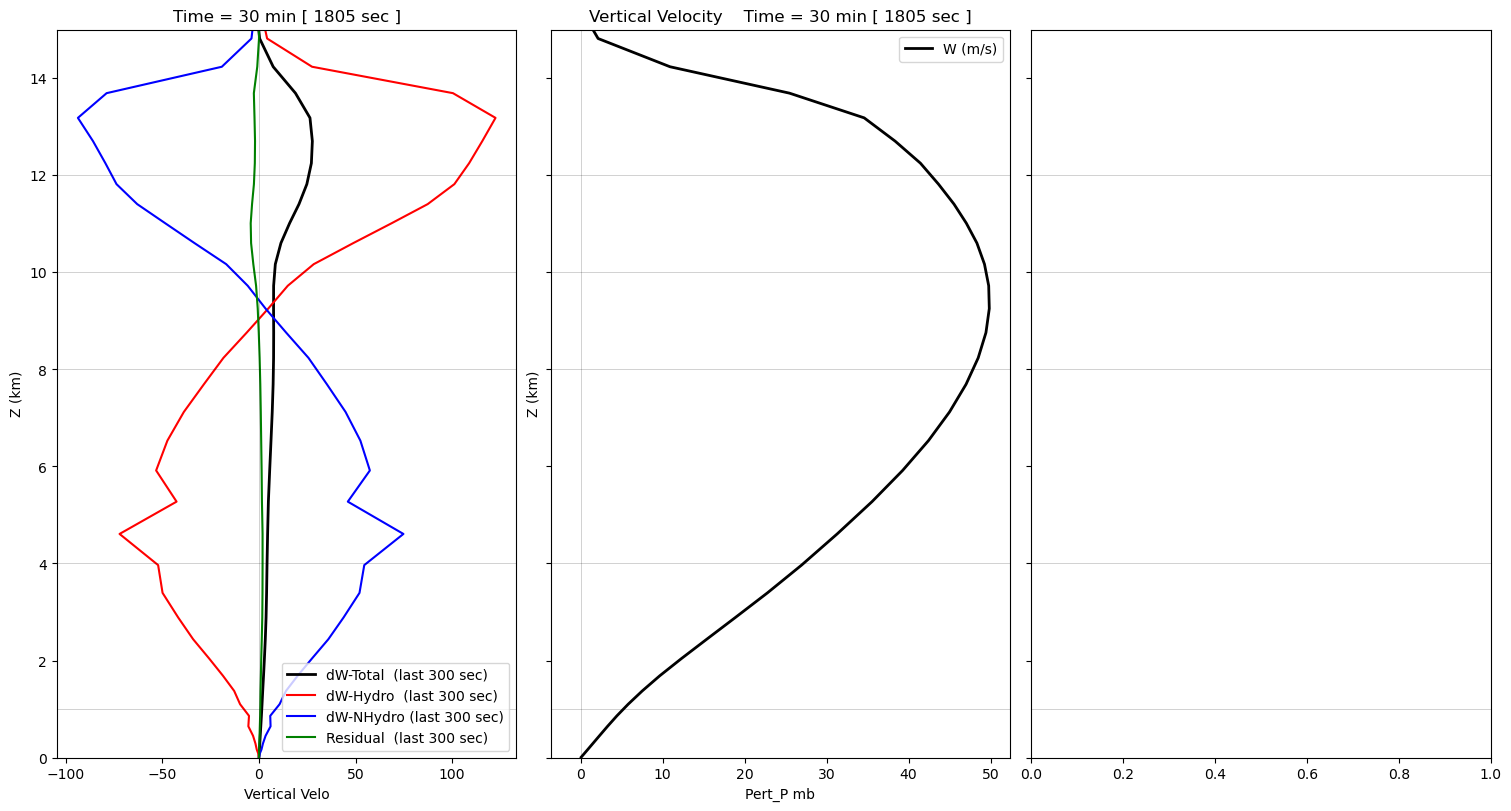

In [53]:
import numpy as np
import matplotlib.pyplot as plt

file = '/work/wicker/climate_runs/FV3_Solo/bubble/euler/3km/QV14/fort.71'

nstep = 720

ze     = []
w_old  = []
w_new  = []
dzdt   = []
nh_pC  = []
nh_pC2 = []
nh_pE  = []
phyd   = []
nh_div = []

with open(file, 'r') as file:
    for line in file:
        columns_as_strings = line.strip().split()
        try:
            numerical_columns = [float(col) for col in columns_as_strings]
            ze.append(numerical_columns[0])
            w_old.append(numerical_columns[1])
            w_new.append(numerical_columns[2])
            dzdt.append(numerical_columns[3])
            nh_pC.append(numerical_columns[4])
            nh_pE.append(numerical_columns[5])
            nh_pC2.append(numerical_columns[6])
            nh_div.append(numerical_columns[7])
            phyd.append(numerical_columns[8])
        except ValueError:
            print(f"Skipping line due to non-numeric data: {line.strip()}")

ze    = np.array(ze).reshape(nstep,50)
w_old = np.array(w_old).reshape(nstep,50)
w_new = np.array(w_new).reshape(nstep,50)
dzdt  = np.array(dzdt).reshape(nstep,50)
nh_pC = np.array(nh_pC).reshape(nstep,50)/100.
nh_pC2 = np.array(nh_pC2).reshape(nstep,50)/100.
nh_pE = np.array(nh_pE).reshape(nstep,50)/100.
phyd  = np.array(phyd).reshape(nstep,50)/100.
nh_div  = np.array(nh_div).reshape(nstep,50)/100.

# fix up the heights

zc       = np.zeros_like(w_old)
zc[:,0]  = 0.5*ze[:,0]
zc[:,1:] = 0.5*(ze[:,1:,] + ze[:,:-1])

ze = ze / 1000.
zc = zc / 1000.

dp_unicode = "\u0394p"

dw = w_new - w_old

tblock = 60 # each time step is 5 sec, so tblock*5 = 300

for t in [61, 120, 180, 240, 300, 360]:

    fig, axes = plt.subplots(1, 3, sharey=True, constrained_layout=True, figsize=(15,8))

    tt = t+1
    time_sec = tt*5 
    time_min = time_sec // 60

    # sum up the change in W due to last 5 min of vertical solver.
    slice = dw[t-tblock:t+1]
    dw_nhydro = np.sum(slice, axis=0)

    # Compute the w-increment from last 5 mins
    dw_new = w_new[t+1,:] - w_new[t-tblock,:]
    
    # sum up the change in W due to last 5 min of horizontal solver
    slice    = w_old[t-tblock:t+1,:] - w_new[t-tblock-1:t,:]
    dw_hydro = np.sum(slice, axis=0)

    budget = dw_new - dw_hydro - dw_nhydro

    axes[0].plot(dw_new,    zc[t,:], color='k', linewidth=2.0, label='dW-Total  (last 300 sec)')
    axes[0].plot(dw_hydro,  zc[t,:], color='r', label='dW-Hydro  (last 300 sec)')
    axes[0].plot(dw_nhydro, zc[t,:], color='b', label='dW-NHydro (last 300 sec)')
    axes[0].plot(budget,    zc[t,:], color='g', label='Residual  (last 300 sec)')
    
    axes[0].set_title(f"Time = {time_min} min [ {time_sec} sec ]")
    axes[0].set_xlabel("Vertical Velo")
    axes[0].set_ylabel("Z (km)")
    axes[0].legend()

    axes[1].plot(w_new[t,:], zc[t,:], color='k', linewidth=2.0, label='W (m/s)')
    # axes[1].plot(nh_pC[t,:], zc[t,:], color='k', label='NH pertC-before')
    # axes[1].plot(nh_pC2[t,:], zc[t,:], color='k', label='NH pertC-after')
    # axes[1].plot(nh_pE[t,:], ze[t,:], color='r', label='NH pert Spline Interp')
    axes[1].set_title(f"Vertical Velocity    Time = {time_min} min [ {time_sec} sec ]")
    axes[1].set_ylim(0.0,15.)
    axes[1].set_xlabel(f"Pert_P mb")
    axes[1].set_ylabel("Z (km)")
    axes[1].legend()
    
    # axes[2].plot(dzdt[t,:], zc[t,:], color='k', label='Hydrostatic Pressure Profile')
    # axes[2].plot(dzt[:], zc[t,:], color='r', label='Hydrostatic Pressure Profile')

    # axes[2].set_title(f"Hydrostatic P (mb) Time = {time_min} min [ {time_sec} sec ]")
    # axes[2].set_xlabel("Hydrostatic P")
    # axes[2].set_ylabel("Z (km)")

# other lines of interest
    for hgt in [1,4, 8,10,12]:
        axes[0].axhline(y = hgt, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )
        axes[1].axhline(y = hgt, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )
        axes[2].axhline(y = hgt, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )

    # for w in [-20,-10,0,10,20]:
    #     axes[0].axvline(x = w, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )

    axes[0].axvline(x = 0.0, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )
    axes[1].axvline(x = 0.0, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )

    plt.savefig("../Figures/Bubble_VerticalSolver_TIME_%2.2d_min.pdf" % time_min)


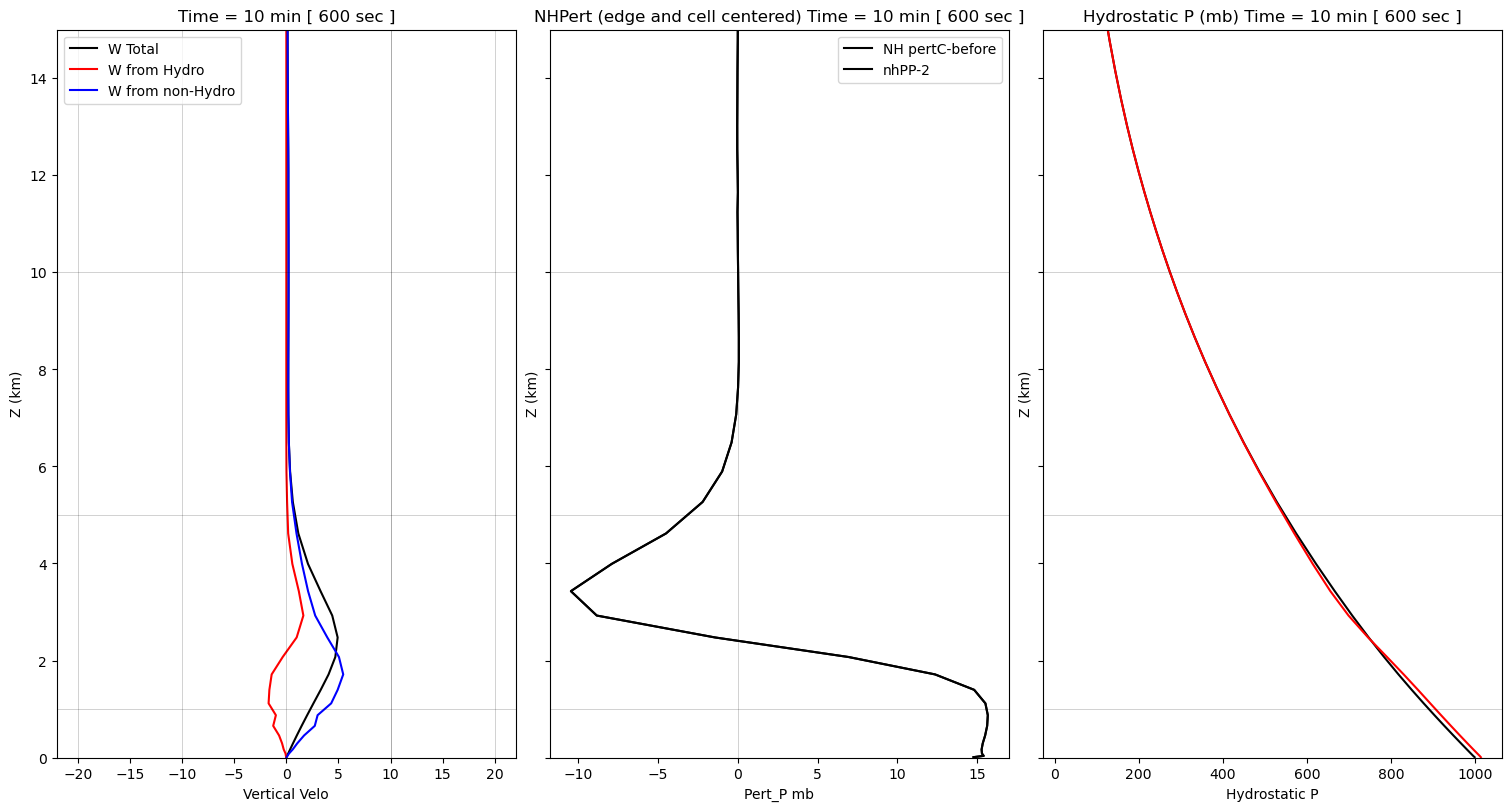

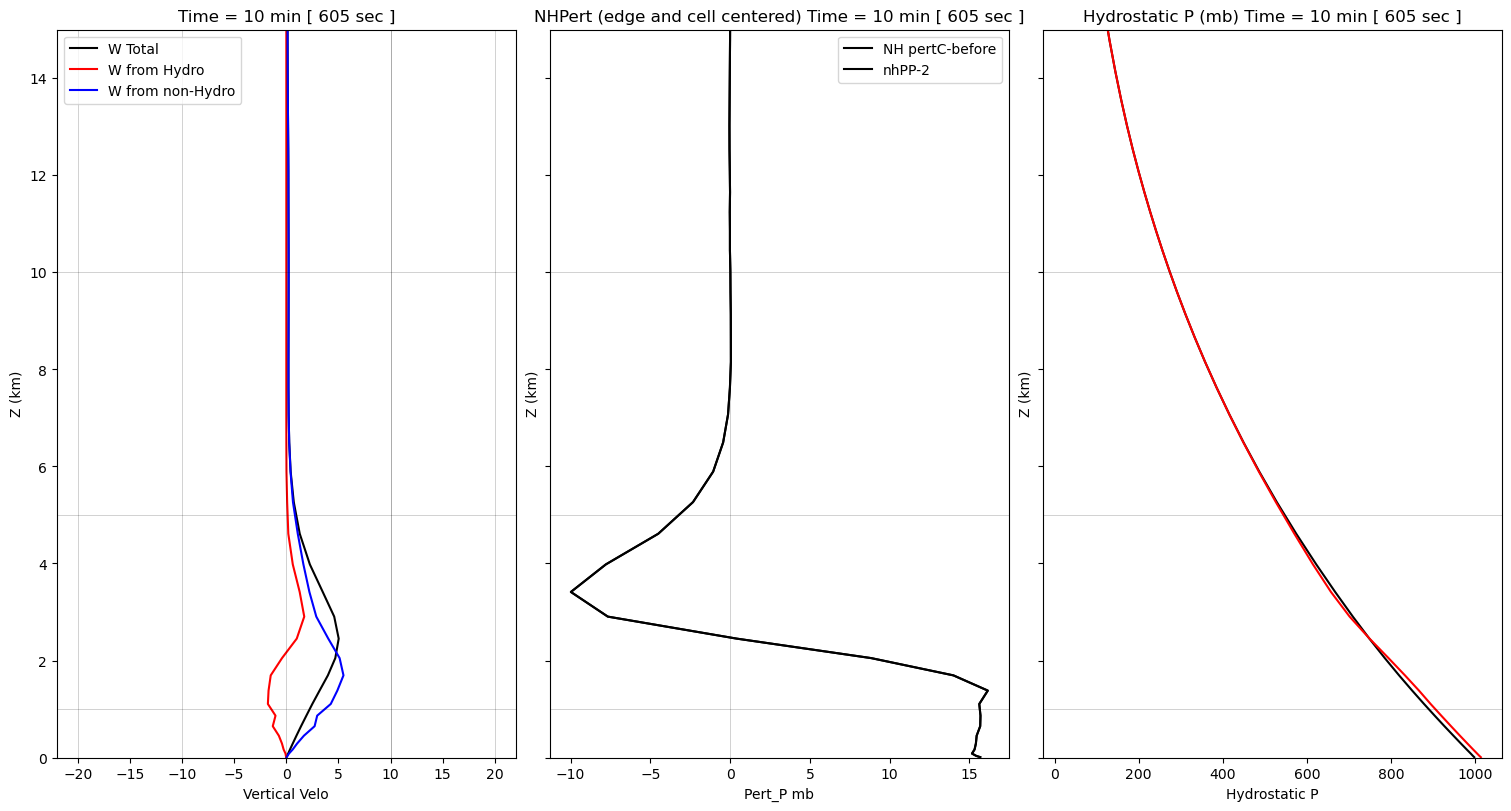

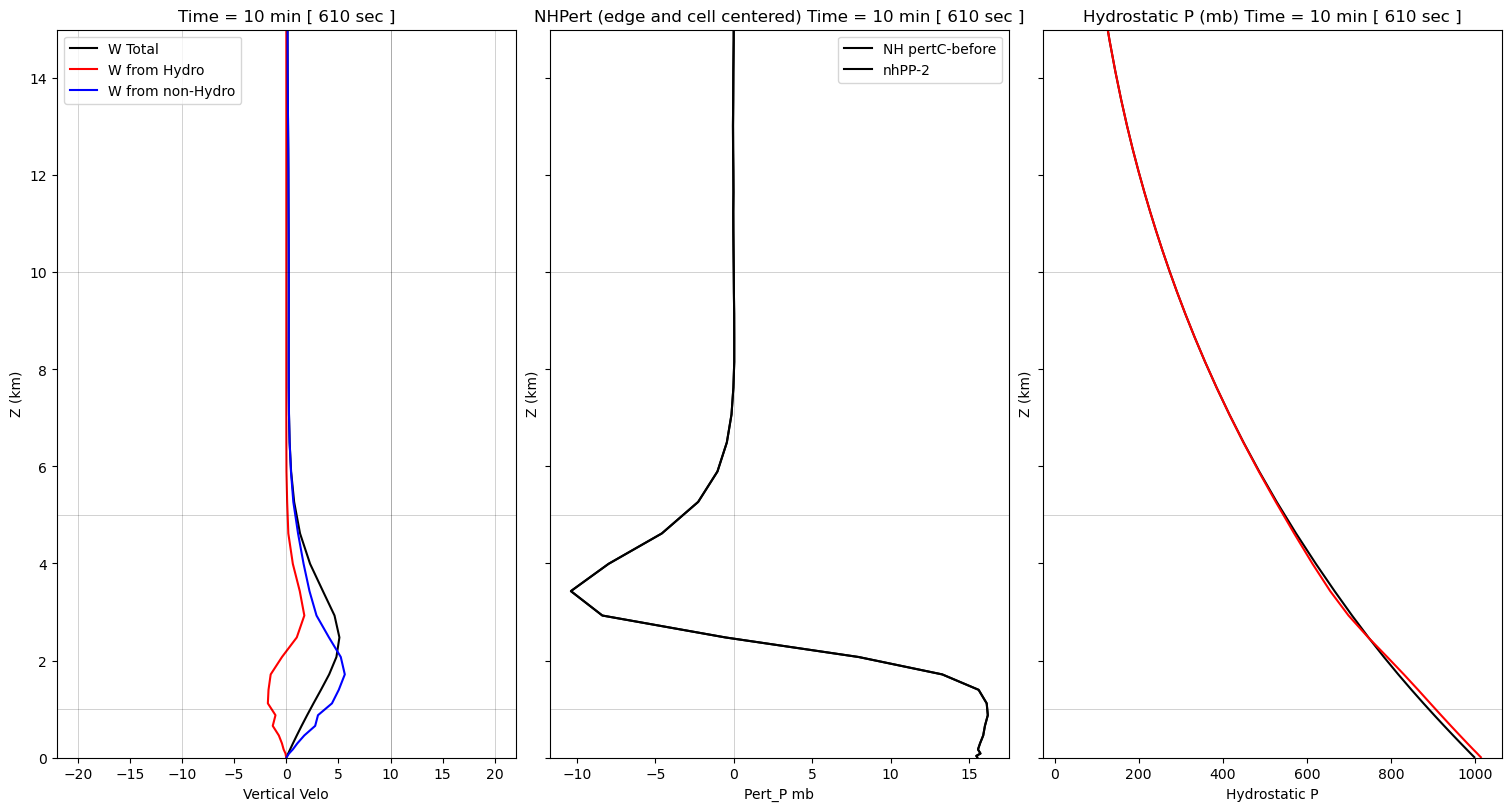

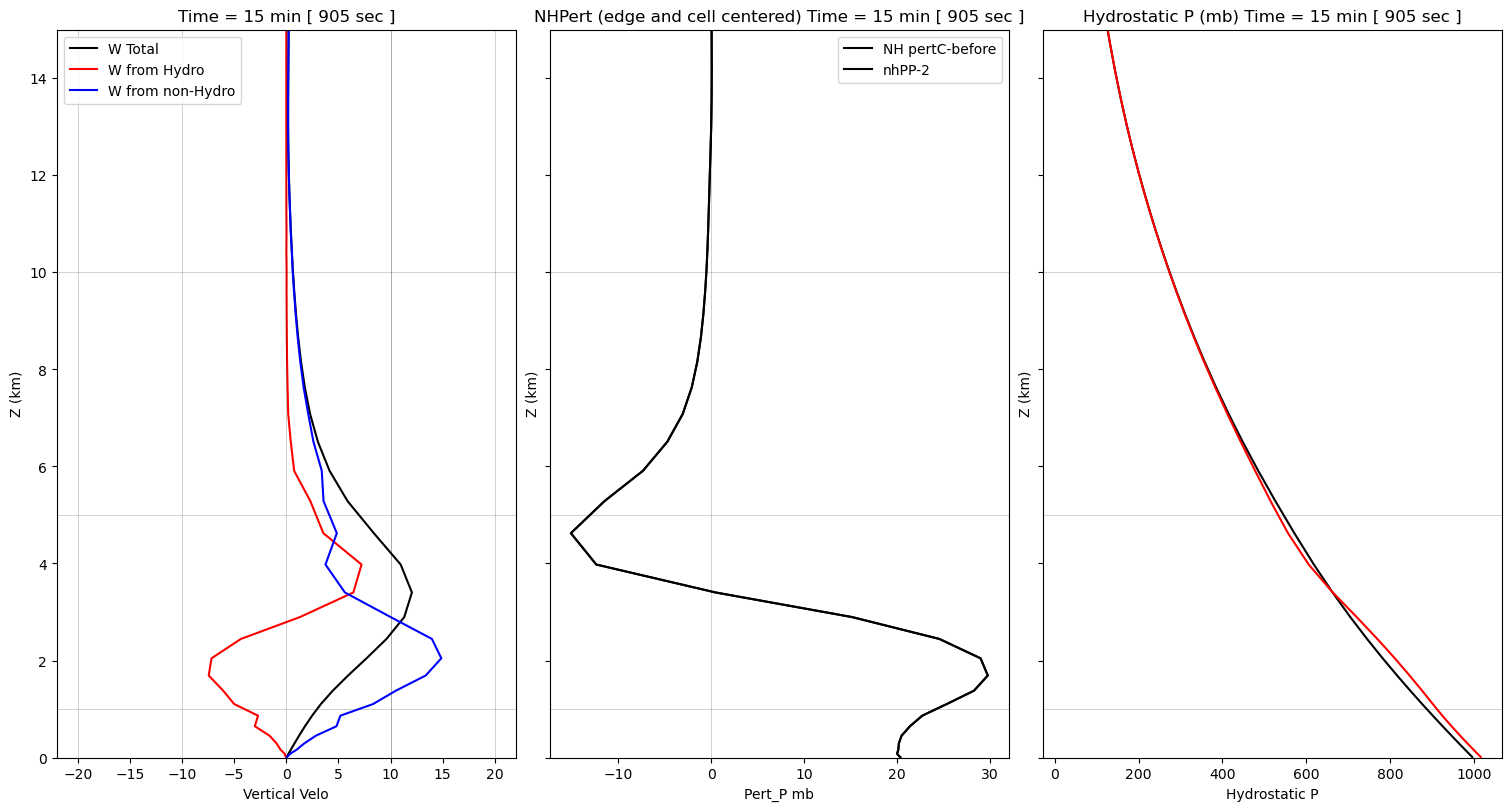

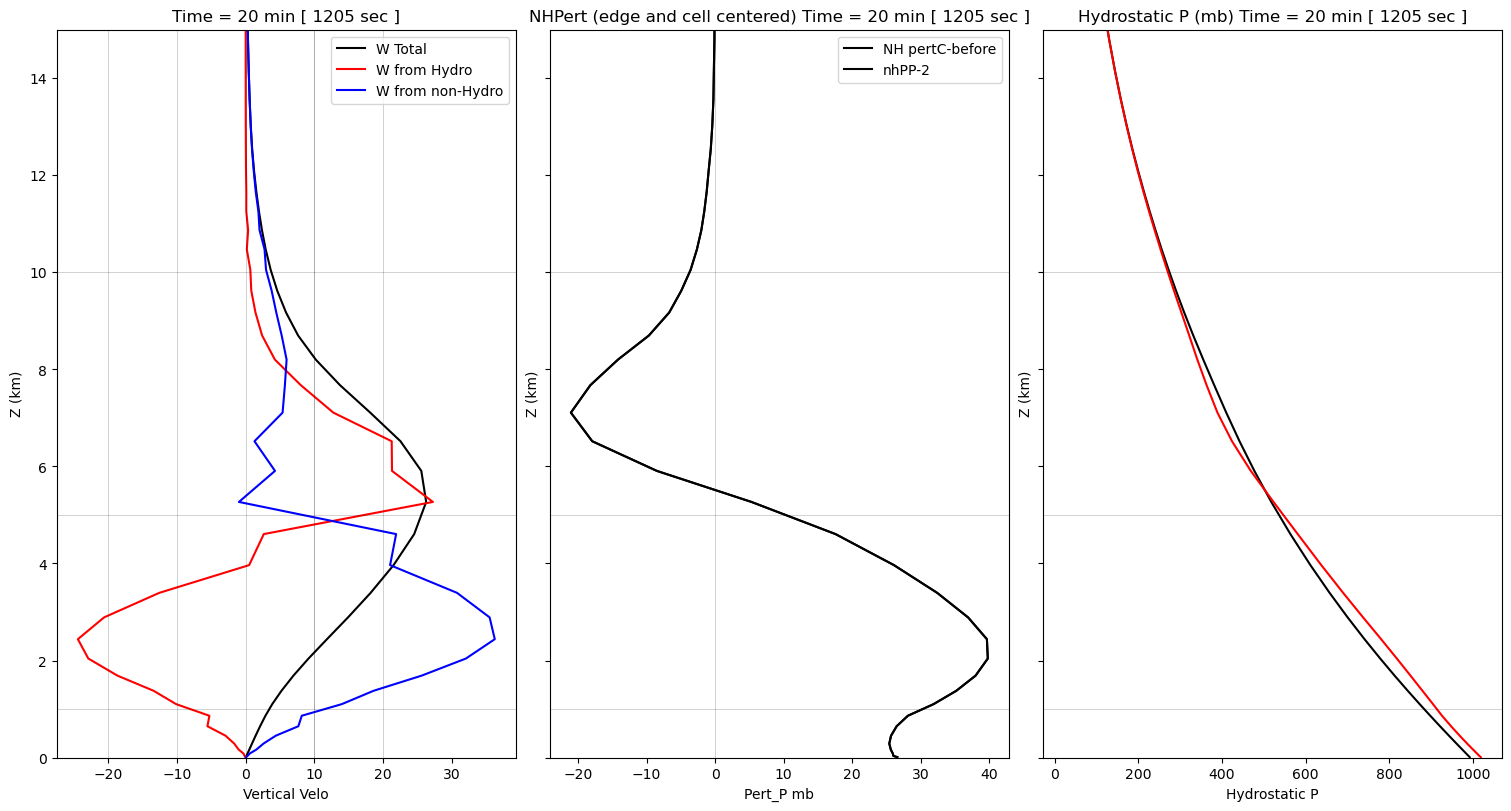

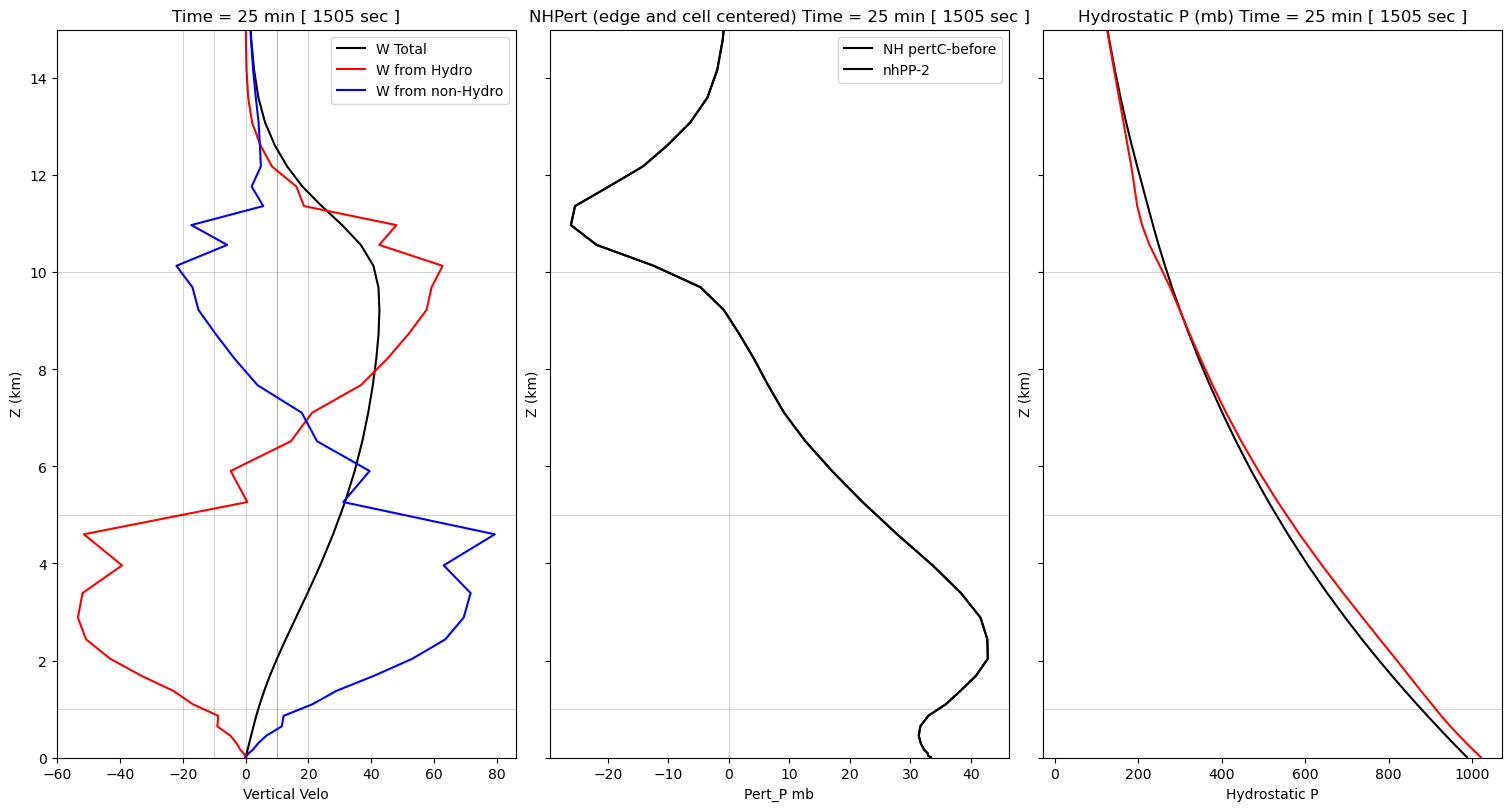

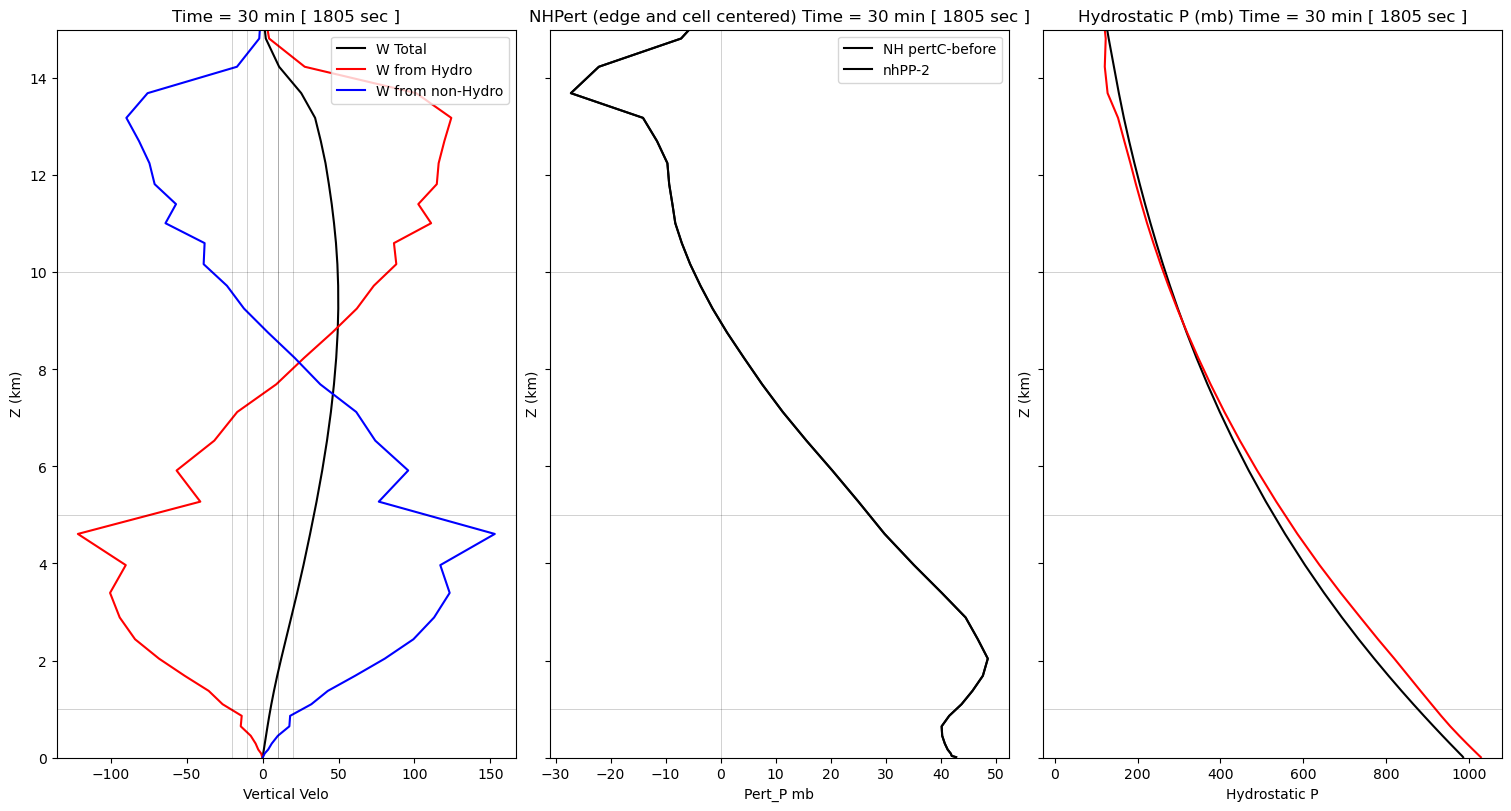

In [84]:
import numpy as np
import matplotlib.pyplot as plt

file = '/work/wicker/climate_runs/FV3_Solo/bubble/euler/3km/QV14/fort.71'

nstep = 720

ze     = []
w_old  = []
w_new  = []
dzdt   = []
nhPP   = []
nh_pC2 = []
nh_pE  = []
pm2    = []
nhP    = []

with open(file, 'r') as file:
    for line in file:
        columns_as_strings = line.strip().split()
        try:
            numerical_columns = [float(col) for col in columns_as_strings]
            ze.append(numerical_columns[0])
            w_old.append(numerical_columns[1])
            w_new.append(numerical_columns[2])
            dzdt.append(numerical_columns[3])
            nhPP.append(numerical_columns[4])
            nh_pE.append(numerical_columns[5])
            nh_pC2.append(numerical_columns[6])
            nhP.append(numerical_columns[7])
            pm2.append(numerical_columns[8])
        except ValueError:
            print(f"Skipping line due to non-numeric data: {line.strip()}")

ze     = np.array(ze).reshape(nstep,50)
w_old  = np.array(w_old).reshape(nstep,50)
w_new  = np.array(w_new).reshape(nstep,50)
dzdt   = np.array(dzdt).reshape(nstep,50)
nhPP   = np.array(nhPP).reshape(nstep,50)/100.
nh_pC2 = np.array(nh_pC2).reshape(nstep,50)/100.
nh_pE  = np.array(nh_pE).reshape(nstep,50)/100.
pm2    = np.array(pm2).reshape(nstep,50)/100.
nhP    = np.array(nhP).reshape(nstep,50)/100.

dp_unicode = "\u0394p"

# fix up the heights

zc       = np.zeros_like(w_old)
zc[:,0]  = 0.5*ze[:,0]
zc[:,1:] = 0.5*(ze[:,1:,] + ze[:,:-1])

ze = ze / 1000.
zc = zc / 1000.

# create increment of w from v-solver

dw = w_new - w_old

for tt in [120, 121, 122, 181, 241, 301, 361]:

    fig, axes = plt.subplots(1, 3, sharey=True, constrained_layout=True, figsize=(15,8))

    t = tt-1
    time_sec = tt*5 
    time_min = time_sec // 60

    slice = dw[:t+1]
    
    nh_sum = np.sum(slice, axis=0)

    axes[0].plot(w_new[t,:], zc[t,:], color='k', label='W Total')
    axes[0].plot(w_new[t,:]-nh_sum, zc[t,:], color='r', label='W from Hydro')
    axes[0].plot(nh_sum, zc[t,:], color='b', label='W from non-Hydro')
    # axes[0].plot(dzdt[t,:], levels[t,:], color='b', label='dz / dt')
    axes[0].set_title(f"Time = {time_min} min [ {time_sec} sec ]")
    axes[0].set_xlabel("Vertical Velo")
    axes[0].set_ylim(0.0,15.)
    axes[0].set_ylabel("Z (km)")
    axes[0].legend()
    
    axes[1].plot(nhPP[t,:], zc[t,:], color='k', label='NH pertC-before')
    axes[1].plot(nhP[t,:]-pm2[t,:], zc[t,:], color='k', label='nhPP-2')
    axes[1].set_title(f"NHPert (edge and cell centered) Time = {time_min} min [ {time_sec} sec ]")
    axes[1].set_ylim(0.0,15.)
    axes[1].set_xlabel(f"Pert_P mb")
    axes[1].set_ylabel("Z (km)")
    axes[1].legend()
    
    axes[2].plot(pm2[t,:], zc[t,:], color='k', label='Hydrostatic Pressure Profile')
    axes[2].plot(nhP[t,:], zc[t,:], color='r', label='NonHydrostatic Pressure Profile')

    axes[2].set_title(f"Hydrostatic P (mb) Time = {time_min} min [ {time_sec} sec ]")
    axes[2].set_xlabel("Hydrostatic P")
    axes[2].set_ylabel("Z (km)")

# other lines of interest
    for hgt in [1,5,10,15,20,25,30]:
        axes[0].axhline(y = hgt, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )
        axes[1].axhline(y = hgt, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )
        axes[2].axhline(y = hgt, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )

    for w in [-20,-10,0,10,20]:
        axes[0].axvline(x = w, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )

    axes[0].axvline(x = 10.0, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )
    axes[1].axvline(x = 0.0, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )

    plt.savefig("../Figures/Bubble_VerticalSolver_TIME_%2.2d_min.pdf" % time_min)

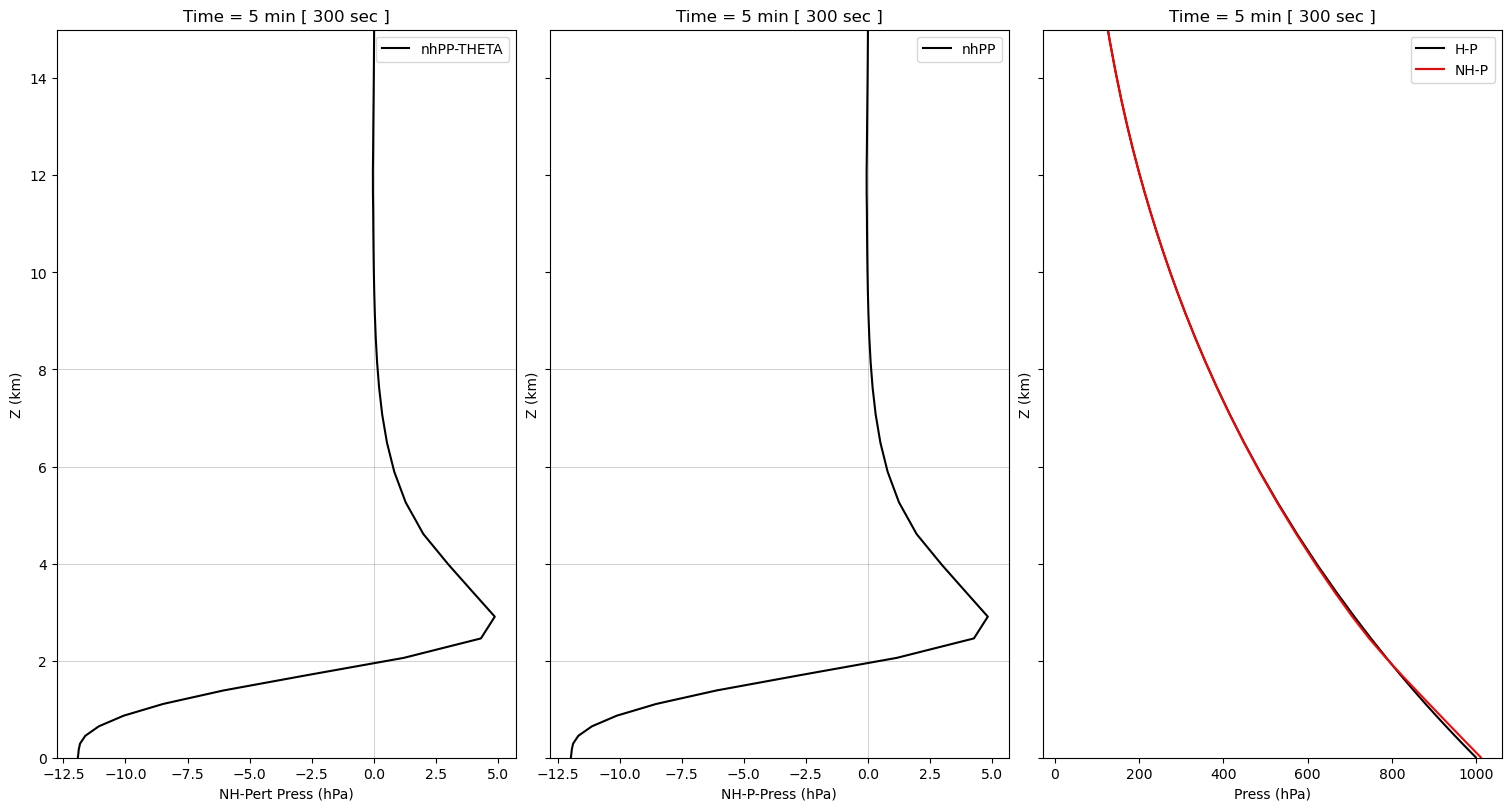

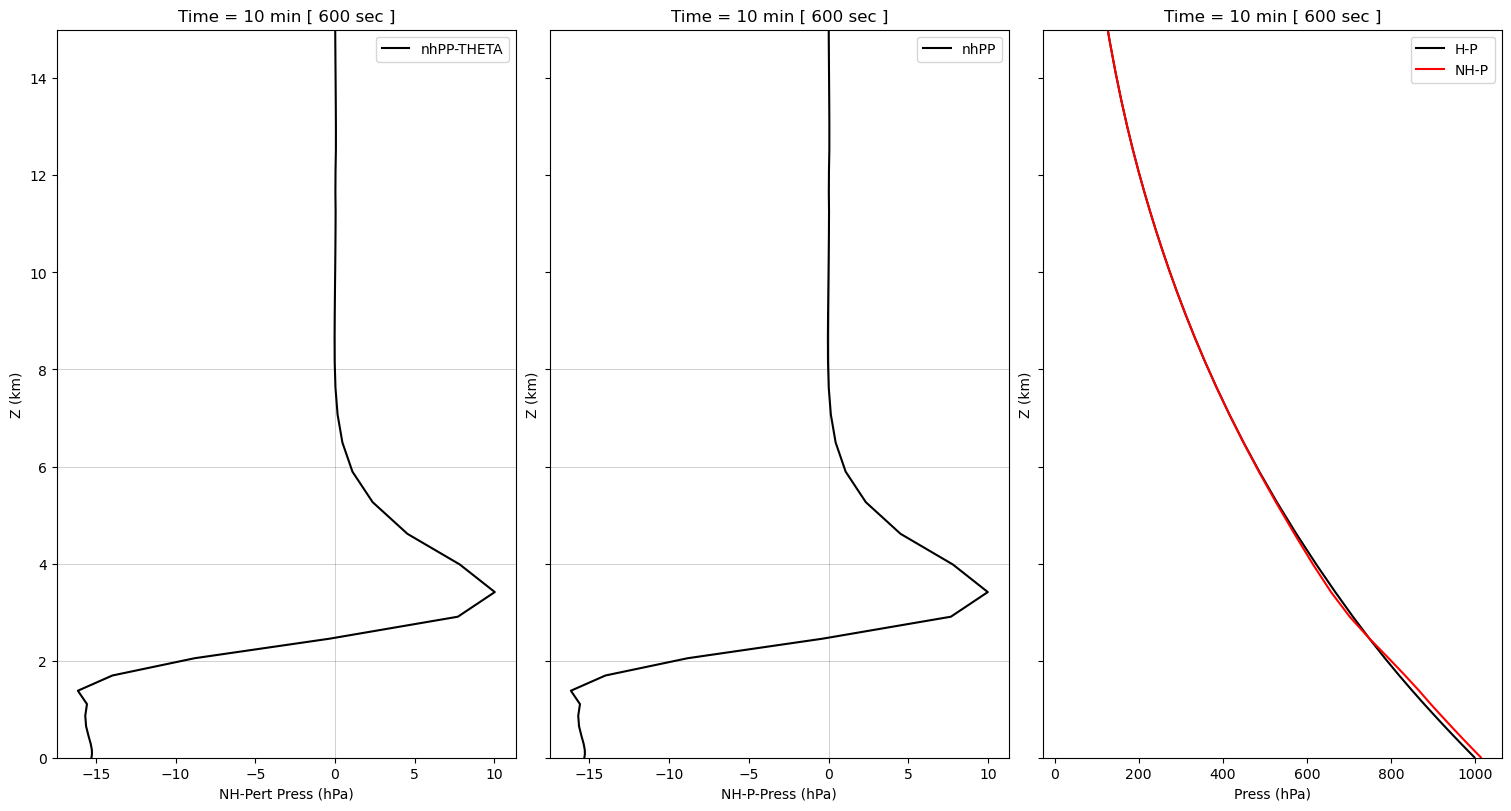

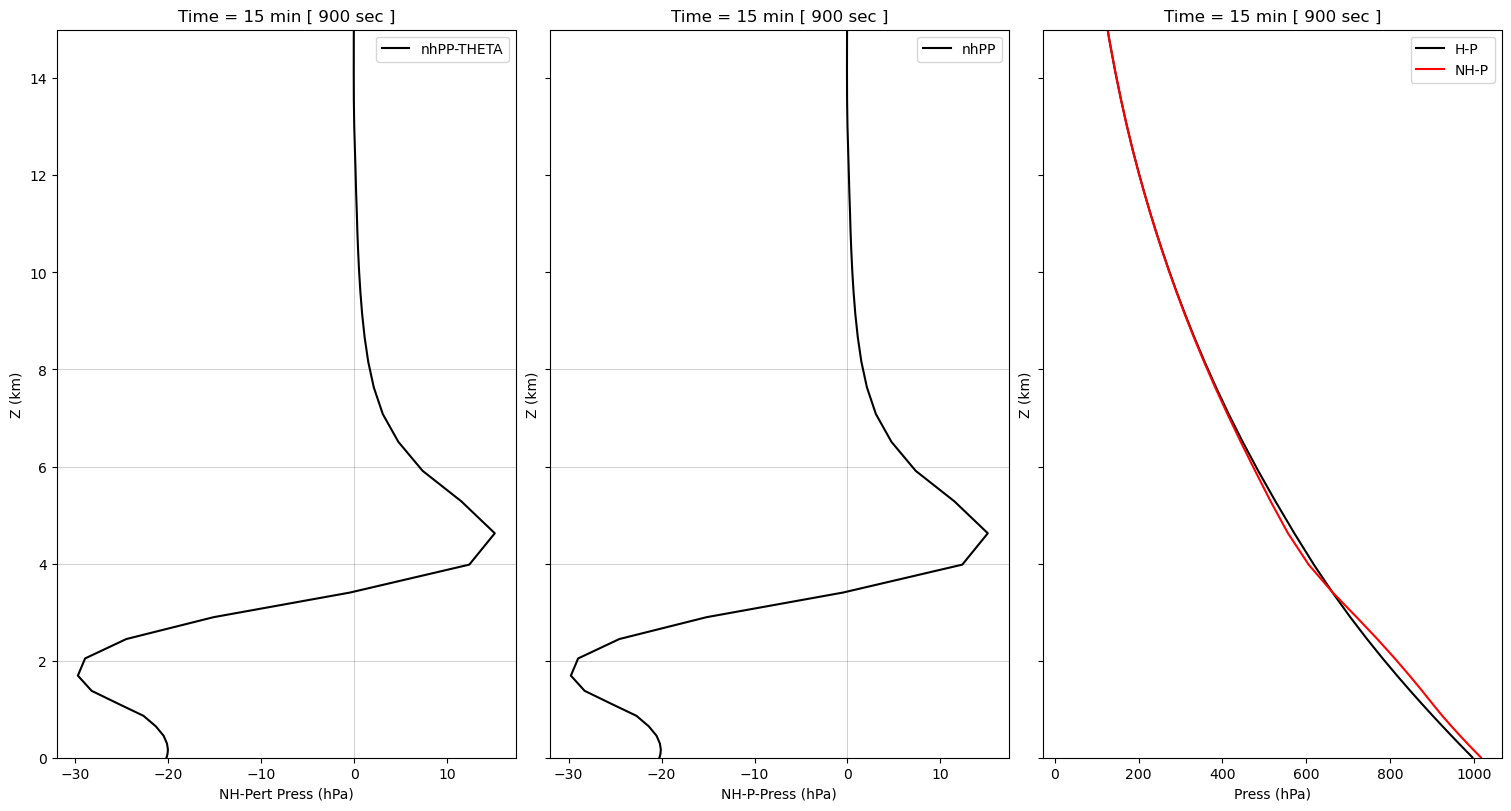

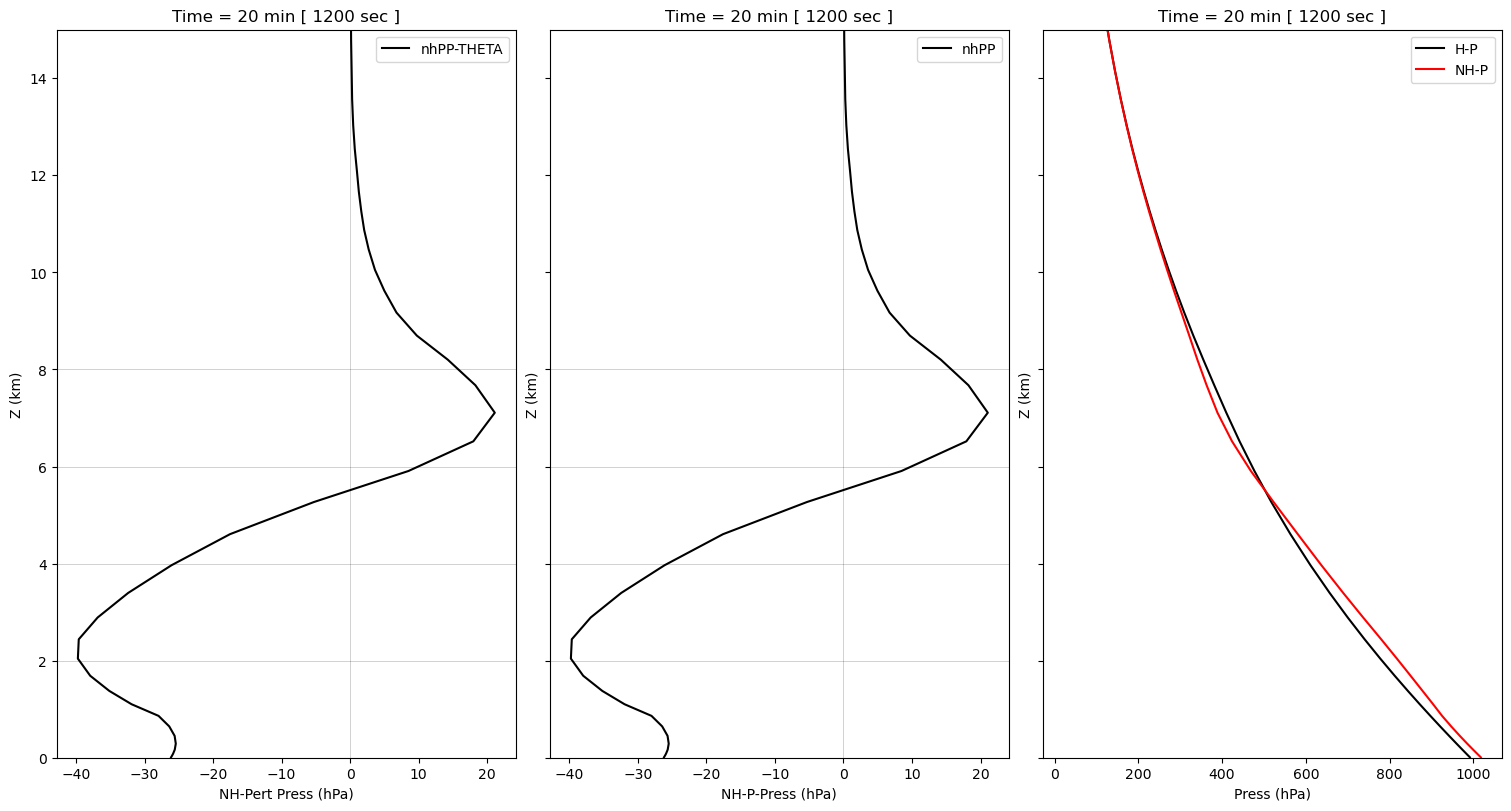

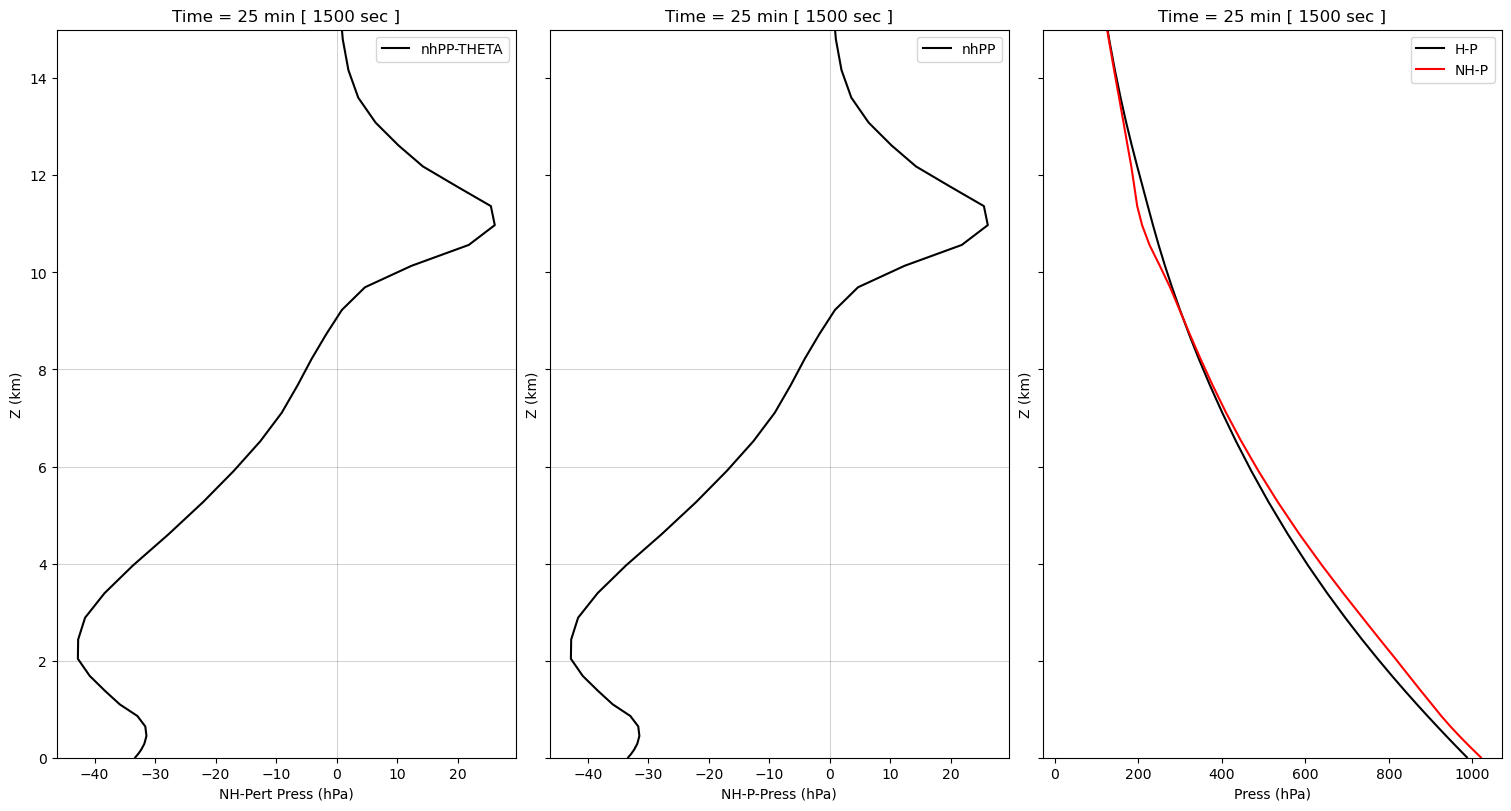

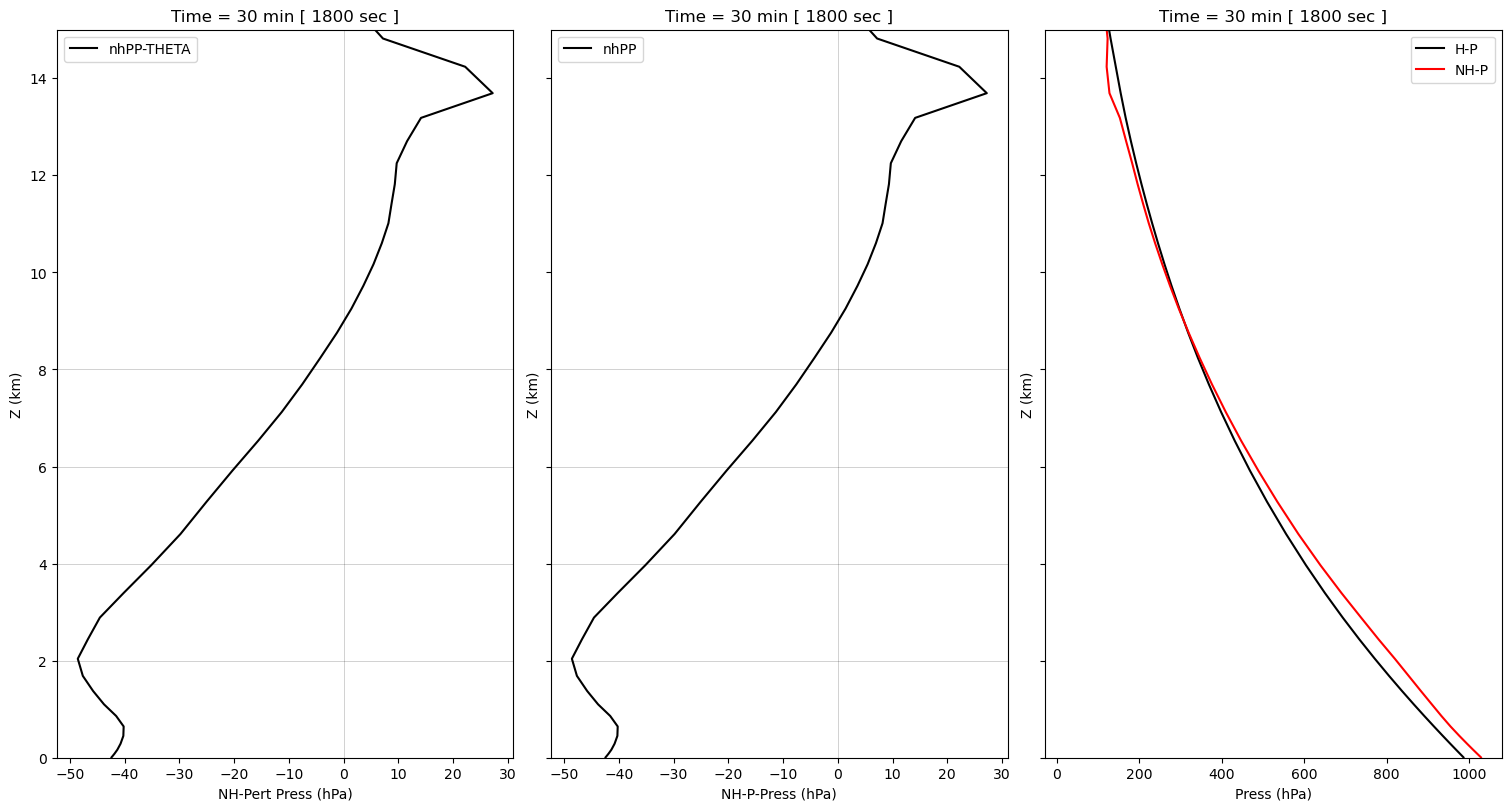

In [144]:
import numpy as np
import matplotlib.pyplot as plt

file = '/work/wicker/climate_runs/FV3_Solo/bubble/euler64/3km/QV14/fort.72'

nstep = 720

ze   = []
pt   = []
pm2  = []
gam  = []
dm2  = []
dz2  = []
nhPP = []

with open(file, 'r') as file:
    for line in file:
        columns_as_strings = line.strip().split()
        try:
            numerical_columns = [float(col) for col in columns_as_strings]
            ze.append(numerical_columns[0])
            nhPP.append(numerical_columns[1])
            pt.append(numerical_columns[2])
            gam.append(numerical_columns[3])
            dm2.append(numerical_columns[4])
            dz2.append(numerical_columns[5])
            pm2.append(numerical_columns[6])
        except ValueError:
            print(f"Skipping line due to non-numeric data: {line.strip()}")

ze     = np.array(ze).reshape(nstep,50)
nhPP   = np.array(nhPP).reshape(nstep,50)
pt     = np.array(pt).reshape(nstep,50)
gam    = np.array(gam).reshape(nstep,50)
pm2    = np.array(pm2).reshape(nstep,50)
dm2    = np.array(dm2).reshape(nstep,50)
dz2    = np.array(dz2).reshape(nstep,50)
rgas   = 287.04

dp_unicode = "\u0394p"

# fix up the heights

zc       = np.zeros_like(w_old)
zc[:,0]  = 0.5*ze[:,0]
zc[:,1:] = 0.5*(ze[:,1:,] + ze[:,:-1])

ze = ze / 1000.
zc = zc / 1000.

nhP = np.exp(gam*np.log(-dm2/dz2*rgas*pt))

# Define the mean (loc) and standard deviation (scale) of the distribution
loc = 0.0   # Mean
scale = 1.0 # Standard deviation

# Generate an array of Gaussian random numbers
# size = 10 # Number of random numbers to generate
# gaussian_array = np.random.uniform(loc, scale, nstep*50).reshape(nstep,50)

# print(gaussian_array.max())

# nhP2 = (-dm2/dz2*rgas*pt)**(gam+0.0001*gaussian_array)

# nhP = (-dm2/dz2*rgas*(pt+0.1*gaussian_array))**(gam)

# print(nhPP.max())

for tt in [61, 121, 181, 241, 301, 361]:

    fig, axes = plt.subplots(1, 3, sharey=True, constrained_layout=True, figsize=(15,8))

    t = tt-1
    time_sec = t*5 
    time_min = time_sec // 60

    slice = dw[:t+1]
    
    nh_sum = np.sum(slice, axis=0)

    # axes[0].plot(pt[t,:], zc[t,:], color='k', label='W Total')
    # axes[0].set_title(f"Time = {time_min} min [ {time_sec} sec ]")
    # axes[0].set_xlabel("potential temp")
    # axes[0].set_ylim(0.0,15.)
    # axes[0].set_ylabel("Z (km)")
    # axes[0].legend()

    axes[1].plot(-nhPP[t,:]/100, zc[t,:], color='k', label='nhPP')
    axes[1].set_title(f"Time = {time_min} min [ {time_sec} sec ]")
    axes[1].set_xlabel("NH-P-Press (hPa)")
    # axes[1].set_xlim(-850,850)
    axes[1].set_ylim(0.0,15.)
    axes[1].set_ylabel("Z (km)")
    axes[1].legend()

    axes[0].plot((pm2[t]-nhP[t])/100., zc[t,:], color='k', label='nhPP-THETA')
    axes[0].set_title(f"Time = {time_min} min [ {time_sec} sec ]")
    axes[0].set_xlabel("NH-Pert Press (hPa)")
    axes[0].set_ylim(0.0,15.)
    axes[0].set_ylabel("Z (km)")
    axes[0].legend()

    axes[2].plot(pm2[t]/100., zc[t,:], color='k', label='H-P')
    axes[2].plot(nhP[t]/100., zc[t,:], color='r', label='NH-P')
    axes[2].set_title(f"Time = {time_min} min [ {time_sec} sec ]")
    axes[2].set_xlabel("Press (hPa)")
    axes[2].set_ylim(0.0,15.)
    axes[2].set_ylabel("Z (km)")
    axes[2].legend()


    for hgt in [2,4,6,8]:
        axes[0].axhline(y = hgt, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )
        axes[1].axhline(y = hgt, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )
    
    axes[0].axvline(x =0.0, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )
    axes[1].axvline(x =0.0, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )

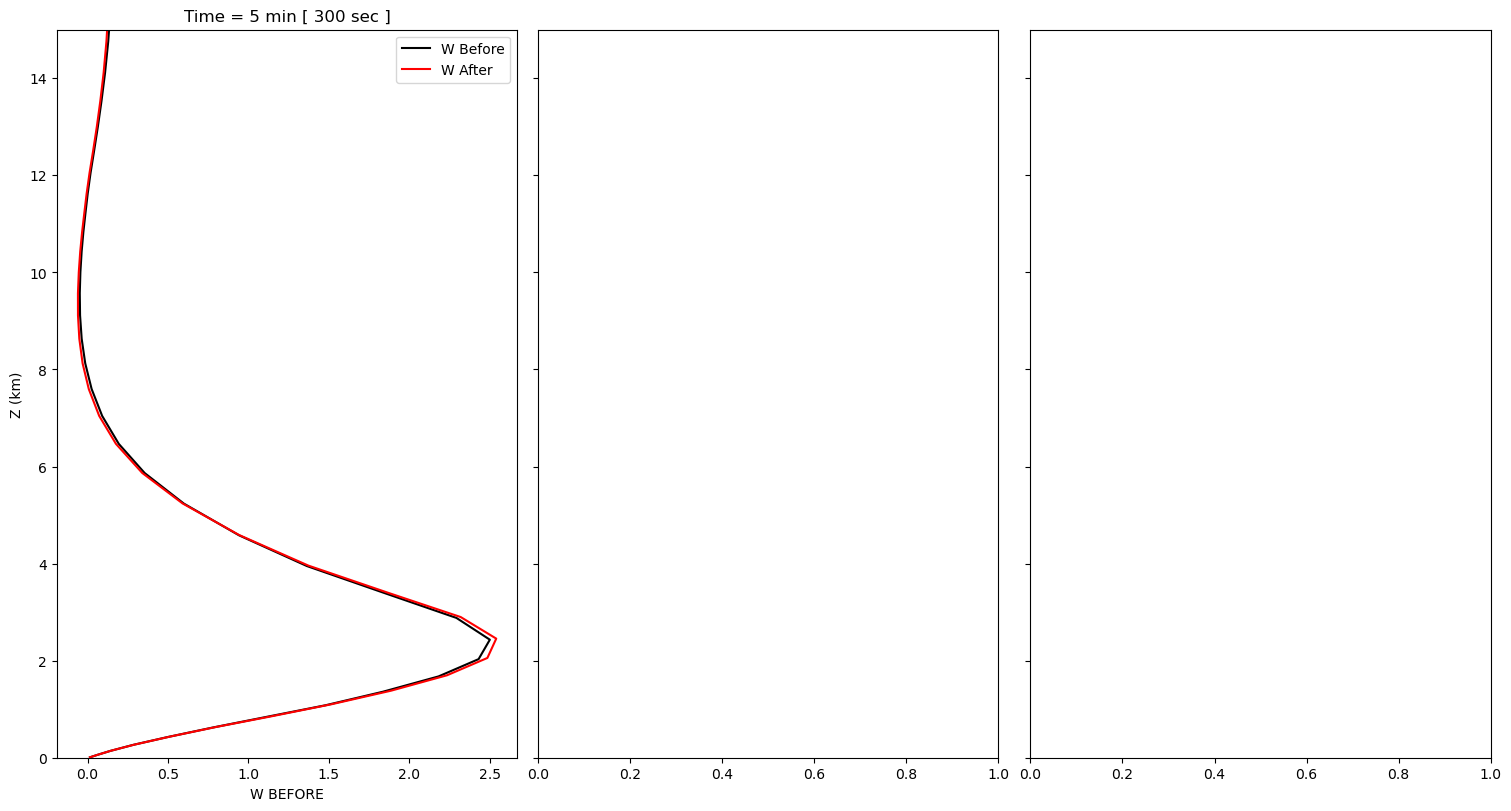

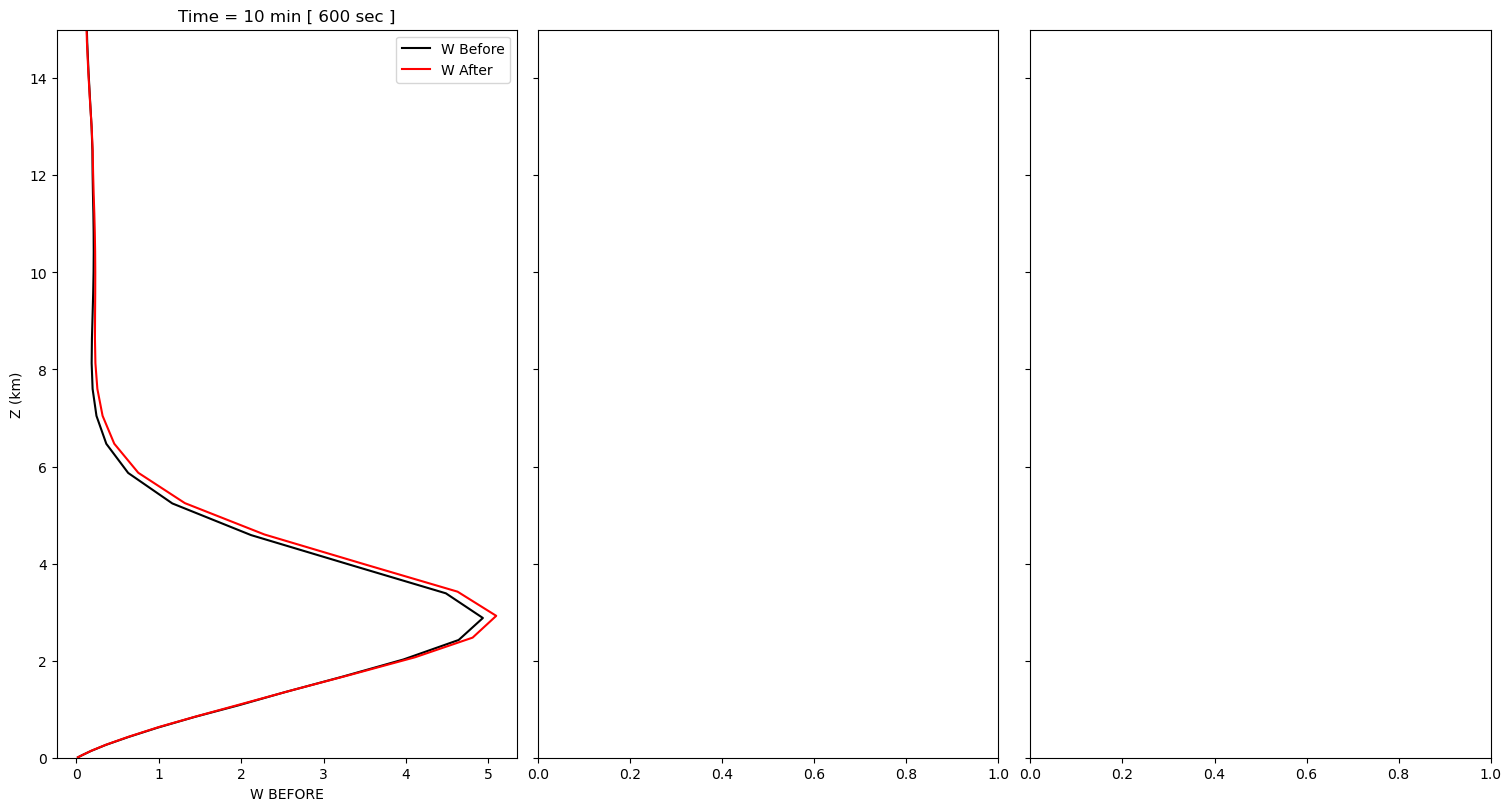

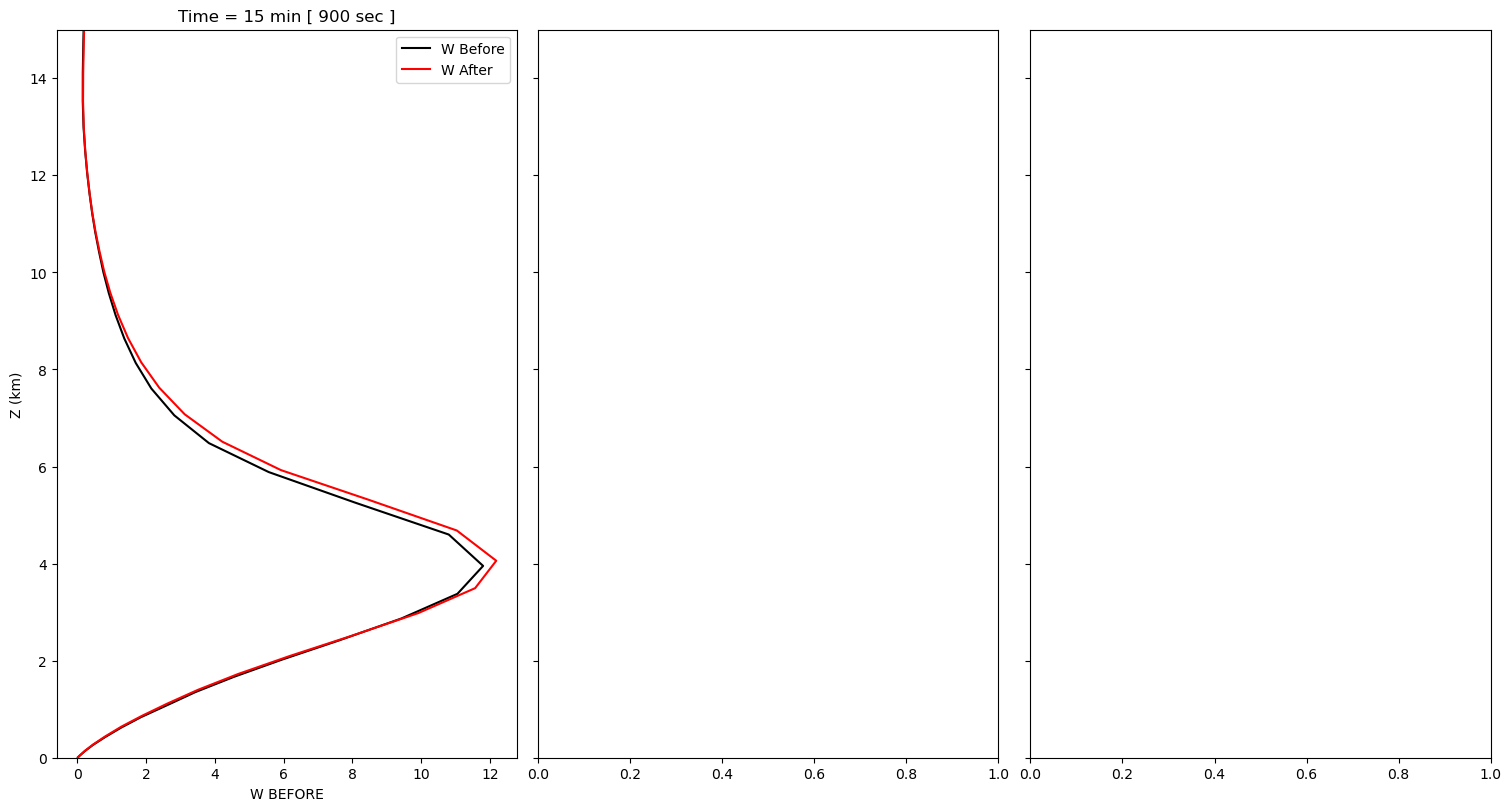

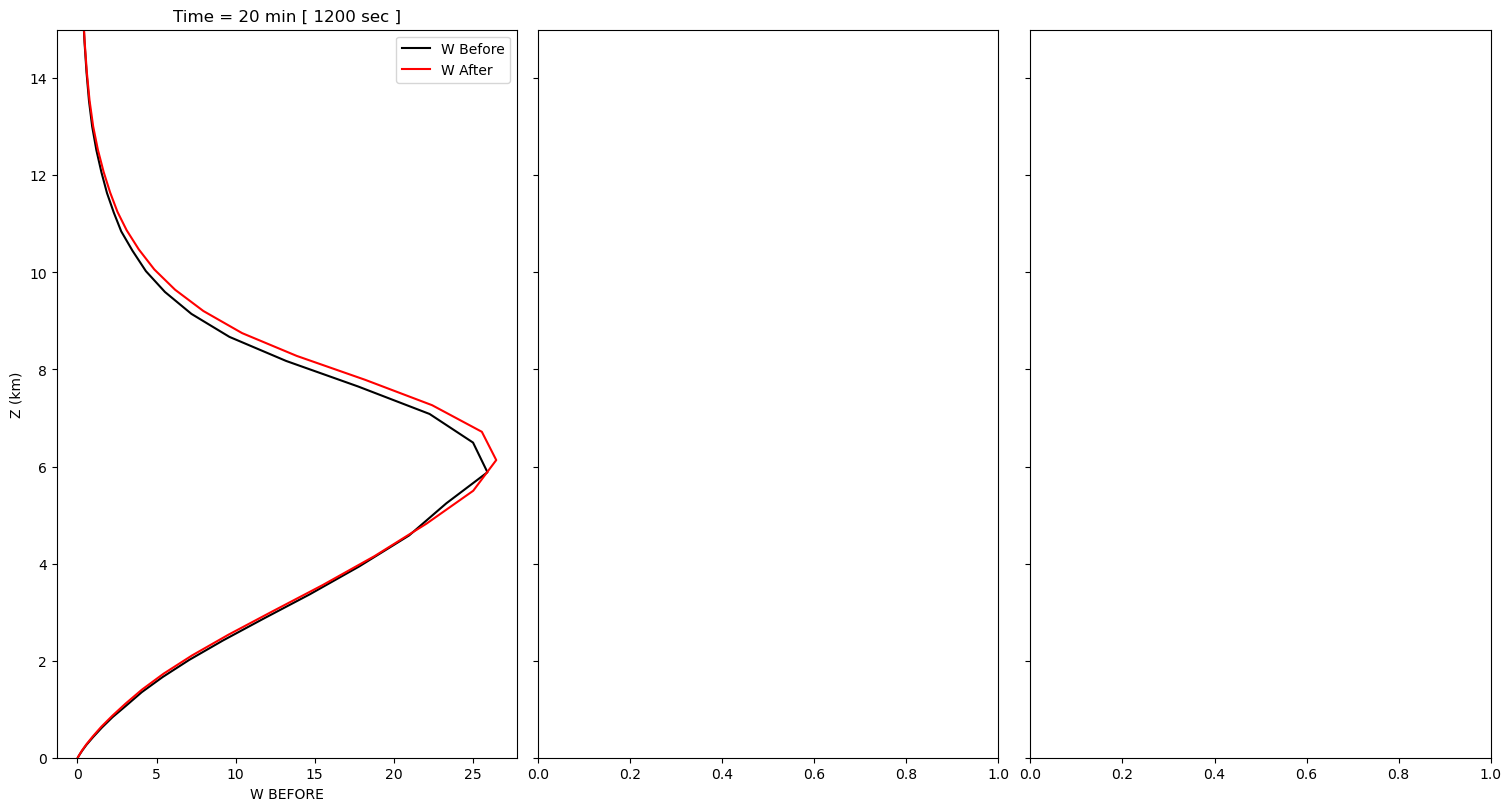

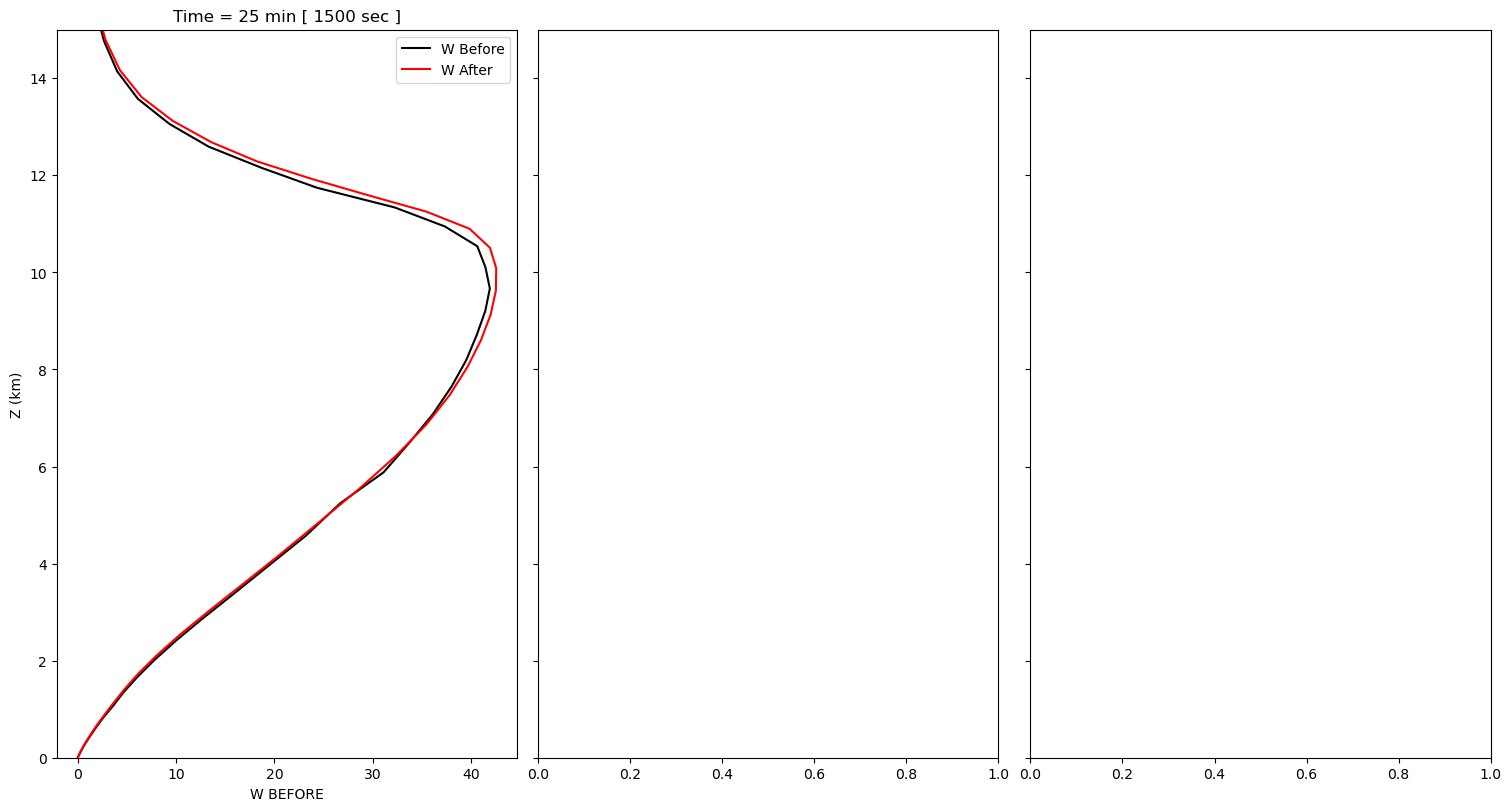

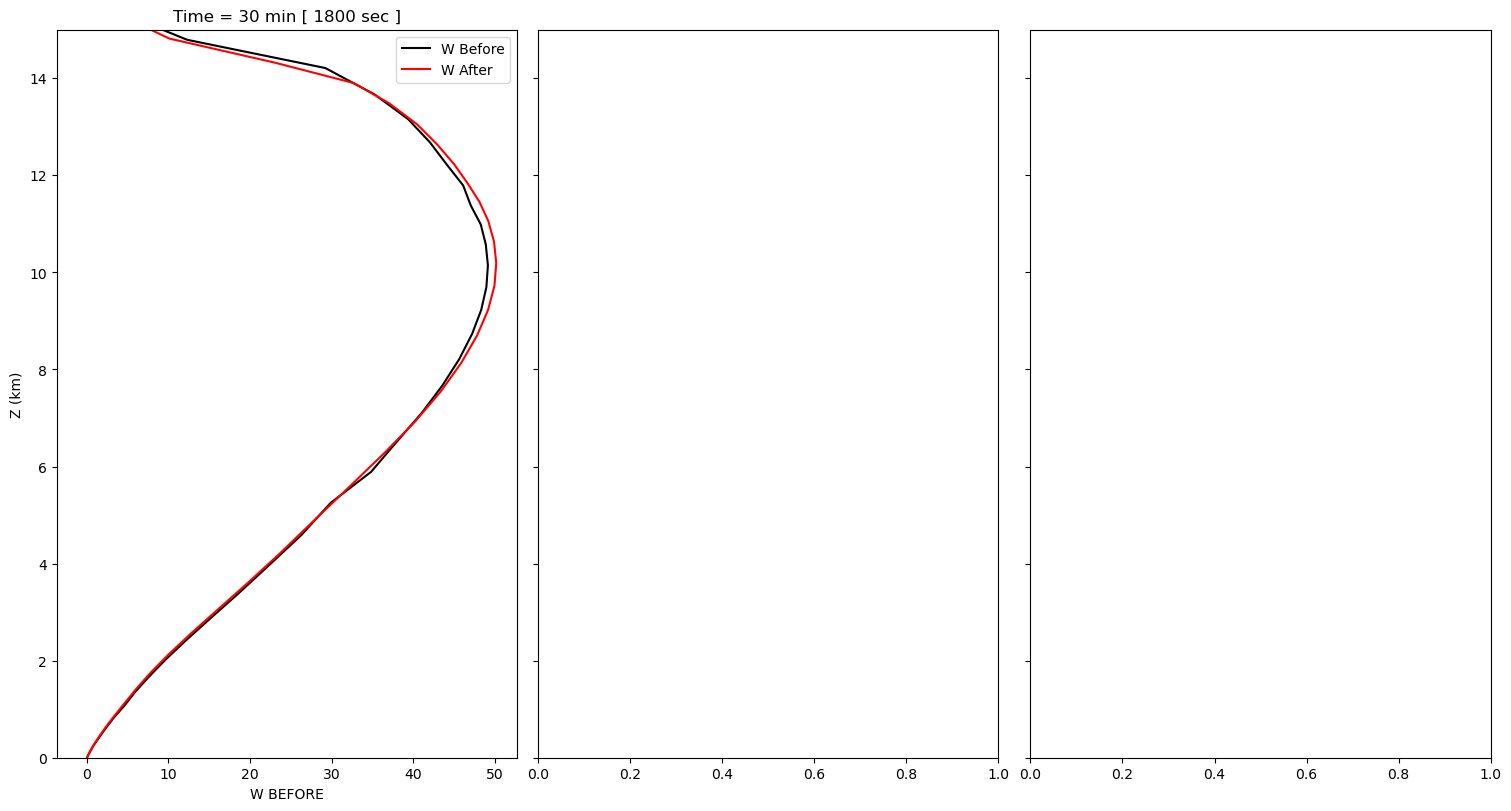

In [164]:
import numpy as np
import matplotlib.pyplot as plt

dp_unicode = "\u0394p"

file1 = '/work/wicker/climate_runs/FV3_Solo/bubble/test_dt/3km/QV14/fort.81'
file2 = '/work/wicker/climate_runs/FV3_Solo/bubble/test_dt/3km/QV14/fort.82'

nstep = 360  # outside of n-step loop?

zb = []
wb = []

with open(file1, 'r') as file:
    for line in file:
        columns_as_strings = line.strip().split()
        try:
            numerical_columns = [float(col) for col in columns_as_strings]
            zb.append(numerical_columns[0])
            wb.append(numerical_columns[1])
        except ValueError:
            print(f"Skipping line due to non-numeric data: {line.strip()}")

zb = np.array(zb).reshape(nstep,50)/1000.
wb = np.array(wb).reshape(nstep,50)

za = []
wa = []

with open(file2, 'r') as file:
    for line in file:
        columns_as_strings = line.strip().split()
        try:
            numerical_columns = [float(col) for col in columns_as_strings]
            za.append(numerical_columns[0])
            wa.append(numerical_columns[1])
        except ValueError:
            print(f"Skipping line due to non-numeric data: {line.strip()}")

za = np.array(za).reshape(nstep,50)/1000.
wa = np.array(wa).reshape(nstep,50)


# fix up the heights


for tt in [31, 61, 91, 121, 151, 181]:

    fig, axes = plt.subplots(1, 3, sharey=True, constrained_layout=True, figsize=(15,8))

    t = tt-1
    time_sec = t*10
    time_min = time_sec // 60

#     slice = dw[:t+1]
    
#     nh_sum = np.sum(slice, axis=0)

    axes[0].plot(wb[t,:], zc[t,:], color='k', label='W Before')
    axes[0].plot(wa[t,:], za[t,:], color='r', label='W After')
    axes[0].set_title(f"Time = {time_min} min [ {time_sec} sec ]")
    axes[0].set_xlabel("W BEFORE")
    axes[0].set_ylim(0.0,15.)
    axes[0].set_ylabel("Z (km)")
    axes[0].legend()

#     axes[1].plot(-nhPP[t,:]/100, zc[t,:], color='k', label='nhPP')
#     axes[1].set_title(f"Time = {time_min} min [ {time_sec} sec ]")
#     axes[1].set_xlabel("NH-P-Press (hPa)")
#     # axes[1].set_xlim(-850,850)
#     axes[1].set_ylim(0.0,15.)
#     axes[1].set_ylabel("Z (km)")
#     axes[1].legend()

#     axes[0].plot((pm2[t]-nhP[t])/100., zc[t,:], color='k', label='nhPP-THETA')
#     axes[0].set_title(f"Time = {time_min} min [ {time_sec} sec ]")
#     axes[0].set_xlabel("NH-Pert Press (hPa)")
#     axes[0].set_ylim(0.0,15.)
#     axes[0].set_ylabel("Z (km)")
#     axes[0].legend()

#     axes[2].plot(pm2[t]/100., zc[t,:], color='k', label='H-P')
#     axes[2].plot(nhP[t]/100., zc[t,:], color='r', label='NH-P')
#     axes[2].set_title(f"Time = {time_min} min [ {time_sec} sec ]")
#     axes[2].set_xlabel("Press (hPa)")
#     axes[2].set_ylim(0.0,15.)
#     axes[2].set_ylabel("Z (km)")
#     axes[2].legend()


#     for hgt in [2,4,6,8]:
#         axes[0].axhline(y = hgt, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )
#         axes[1].axhline(y = hgt, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )
    
#     axes[0].axvline(x =0.0, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )
#     axes[1].axvline(x =0.0, color = 'k', alpha=0.25, linestyle='-', linewidth=0.5 )